# Energy Consumption Forecasting (Time Series)

## Module: AI and Machine Learning (ST1511)

## Assignment: CA2 – Part B

## Student Name: Kendrick Slamat

## Student ID: p2510877


---

## Problem Understanding

**Background:**
We have historical monthly energy consumption data spanning multiple years.
Our goal is to build forecasting models to predict future consumption patterns.

**Business Value:**

-   Energy providers can plan production and manage supply
-   Identify seasonal patterns and trends
-   Optimize resource allocation
-   Cost savings through better planning

**Dataset:** `CA2-Energy-Consumption-Data.csv`

**Targets to Forecast:**

1. Gas Consumption (tons)
2. Electricity Consumption (MWh)
3. Water Consumption (tons)

**Forecast Horizon:** 60 months


---

## Time Series Machine Learning Workflow

The workflow for time series is different from regular ML:

1. **Data Understanding** - Load and explore temporal patterns
2. **Data Preparation** - Handle dates, set frequency, check for gaps
3. **EDA** - Visualize trends, seasonality, and patterns over time
4. **Stationarity Testing** - Check if series is stationary (important for ARIMA!)
5. **Decomposition** - Separate trend, seasonal, and residual components
6. **Train/Val/Test Split** - **CHRONOLOGICAL ONLY** (earliest → latest)
7. **Baseline Model** - Simple model to establish performance benchmark
8. **Model Improvement** - Identify weaknesses → improve → compare
9. **Final Model** - Train on full data, forecast 60 months
10. **Residual Analysis** - Check if model captured all patterns

Let's begin!


---

## SECTION 1: Data Understanding and Preparation

**Objective:** Load data and prepare it for time series analysis.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from scipy import stats
from scipy.stats import shapiro
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf
import itertools

# Suppress warnings
warnings.filterwarnings('ignore')

# pd.set_option('display.max_columns', None)
plt.style.use("dark_background")
color_palette = [
    "#3d7bc5",  
    "#c45b9a",  
    "#2f8a46",  
    "#c56a2f",  
    "#d45a4f",  
    "#6e7681",  
    "#9aa4b1",
]
sns.set_theme(
    context="notebook",
    style="darkgrid",
    palette=color_palette,
    rc={
        "axes.facecolor": "#0d1117",
        "figure.facecolor": "#0d1117",
        "axes.edgecolor": "#30363d",
        "grid.color": "#30363d",
        "text.color": "#c9d1d9",
        "axes.labelcolor": "#c9d1d9",
        "xtick.color": "#8b949e",
        "ytick.color": "#8b949e",
        "axes.titleweight": "bold",
        "axes.titlepad": 14,
        "legend.frameon": False,
        },
)

In [2]:
path = "datasets/CA2-Energy-Consumption-Data.csv"
df = pd.read_csv(path)
print(df.info())
print(df.shape)
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397 entries, 0 to 396
Data columns (total 4 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   DATE                           397 non-null    object 
 1   Gas Consumption (tons)         397 non-null    float64
 2   Electricity Consumption (MWh)  397 non-null    float64
 3   Water Consumption (tons)       397 non-null    float64
dtypes: float64(3), object(1)
memory usage: 12.5+ KB
None
(397, 4)


,DATE,Gas Consumption (tons),Electricity Consumption (MWh),Water Consumption (tons)
0,1/1/1990,18.0,725.1,548.8
1,1/2/1990,15.8,706.7,640.7
2,1/3/1990,17.3,624.5,511.1
3,1/4/1990,18.9,574.7,515.3
4,1/5/1990,22.0,553.2,488.4


**✏️ YOUR OBSERVATIONS:**

Dataset overview:

-   Total rows (months): **397**
-   Date range: **1990-01-01** to **2023-01-01**
-   Number of years: **≈33 years (397 months)**
-   Columns: `DATE`, `Gas Consumption (tons)`, `Electricity Consumption (MWh)`, `Water Consumption (tons)`
-   Data types: DATE parsed to datetime (set as index), targets are `float64`


In [3]:
# Convert to datetime (day/month/year format in dataset)
df['DATE'] = pd.to_datetime(df['DATE'], format='%d/%m/%Y', errors='coerce')

# Sort and set index
df = df.sort_values('DATE')
df.set_index('DATE', inplace=True)
df = df.asfreq('MS')  # Set frequency to Month Start for proper time series operations

In [4]:
# Check for missing values
print(df.isna().sum())

# If missing values found, handle them:
df = df.interpolate(method='time')
df.head()

Gas Consumption (tons)           0
Electricity Consumption (MWh)    0
Water Consumption (tons)         0
dtype: int64


,Gas Consumption (tons),Electricity Consumption (MWh),Water Consumption (tons)
DATE,,,
1990-01-01,18.0,725.1,548.8
1990-02-01,15.8,706.7,640.7
1990-03-01,17.3,624.5,511.1
1990-04-01,18.9,574.7,515.3
1990-05-01,22.0,553.2,488.4


---

## SECTION 2: Exploratory Data Analysis

**Objective:** Understand temporal patterns in the data

**What to look for:**

-   **Trend:** Long-term increase or decrease
-   **Seasonality:** Regular patterns that repeat (monthly, yearly)
-   **Volatility:** How much variation is there?
-   **Outliers:** Unusual spikes or drops


In [5]:
# Display summary statistics
print(df.info())
df.describe()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 397 entries, 1990-01-01 to 2023-01-01
Freq: MS
Data columns (total 3 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Gas Consumption (tons)         397 non-null    float64
 1   Electricity Consumption (MWh)  397 non-null    float64
 2   Water Consumption (tons)       397 non-null    float64
dtypes: float64(3)
memory usage: 12.4 KB
None


,Gas Consumption (tons),Electricity Consumption (MWh),Water Consumption (tons)
count,397.000000,397.000000,397.000000
mean,23.785139,888.472544,484.953652
std,4.903452,153.877594,133.908863
min,11.600000,553.200000,44.400000
25%,20.200000,771.100000,384.400000
50%,23.500000,897.800000,487.400000
75%,27.900000,1005.200000,580.200000
max,46.000000,1294.000000,811.000000


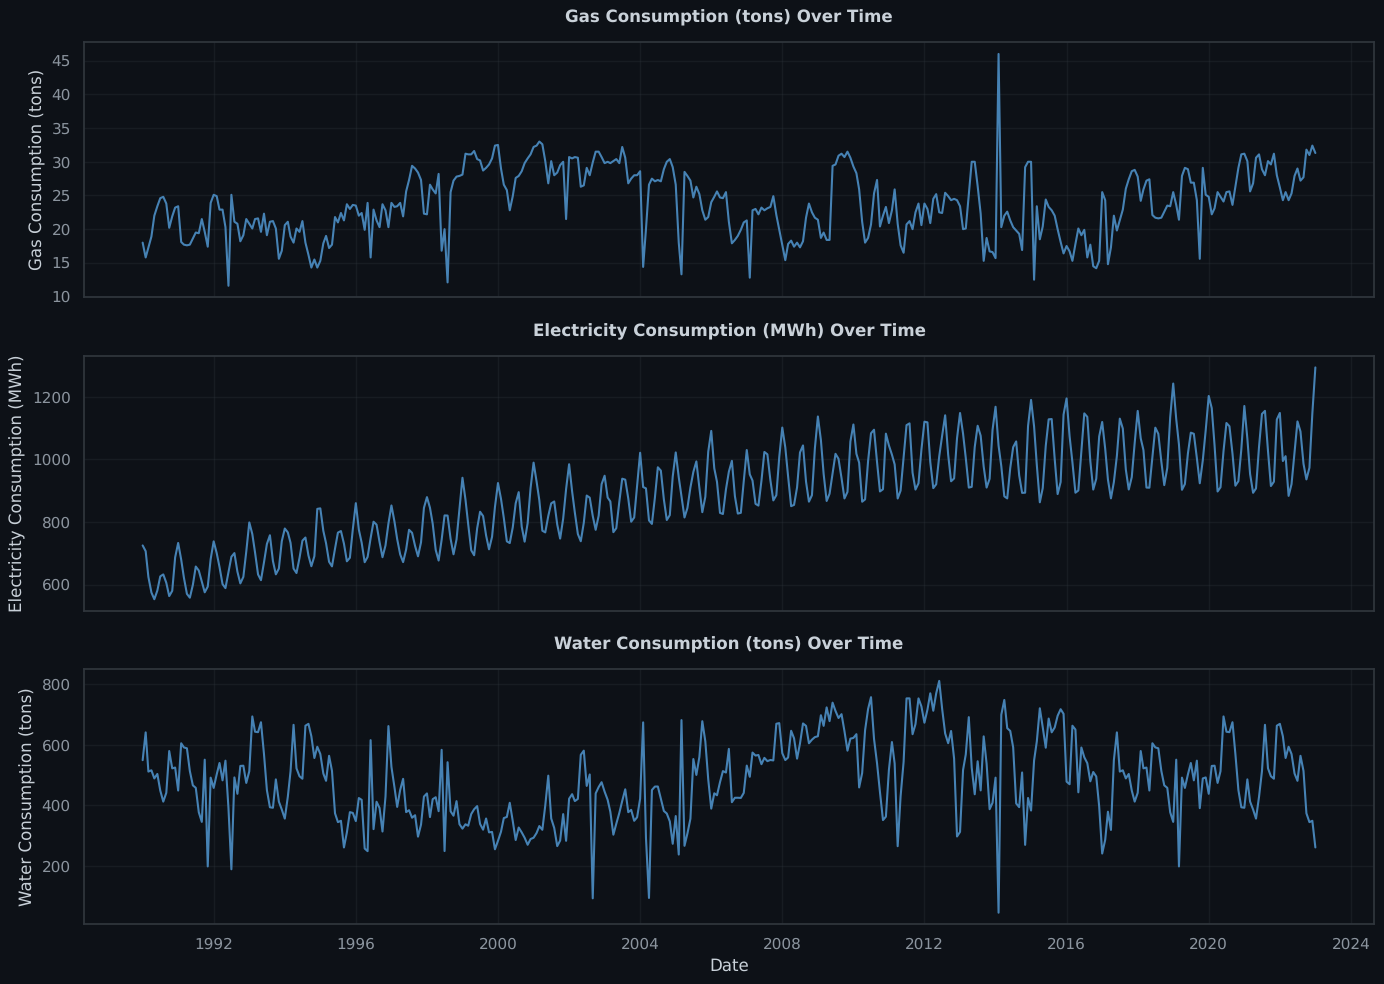

In [6]:
# Plot all three consumption types over time

targets = ['Gas Consumption (tons)', 'Electricity Consumption (MWh)', 'Water Consumption (tons)']

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for idx, target in enumerate(targets):
    axes[idx].plot(df.index, df[target], color='steelblue')
    axes[idx].set_title(f'{target} Over Time')
    axes[idx].set_ylabel(target)
    axes[idx].grid(True, alpha=0.3)

plt.xlabel('Date')
plt.tight_layout()
plt.show()

**✏️ VISUAL OBSERVATIONS:**

From the time series plots:

**Gas Consumption:**

-   Trend: The level fluctuates over time, with a general increase after 2000 and periods of decline around 2005 and 2015.
-   Seasonality: No clear repeating yearly pattern.
-   Volatility: High, with sharp peaks and troughs. There is a single extreme spike in February 2014 (46 tons, the series maximum).

**Electricity Consumption:**

-   Trend: A consistent upward trend over the whole period.
-   Seasonality: A very regular yearly cycle that repeats every 12 months.
-   Volatility: Low apart from the seasonal cycle.

**Water Consumption:**

-   Trend: No consistent direction; the level drifts up and down, with lows around 2000 and 2017.
-   Seasonality: No clear repeating yearly pattern.
-   Volatility: High. February 2014 has an extreme low of 44 tons (the series minimum), in the same month as the gas spike, which suggests a data-recording problem in that month.


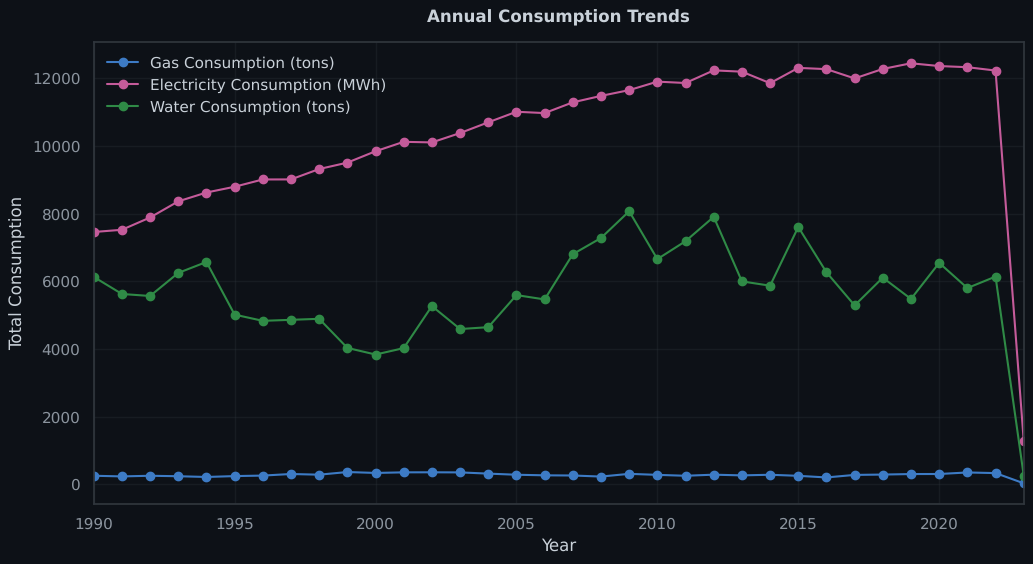

In [7]:
# Resample to annual frequency and sum the consumption values
annual_consumption = df.resample('Y').sum()

annual_consumption.plot(figsize=(12, 6), marker='o')
plt.title('Annual Consumption Trends')
plt.xlabel('Year')
plt.ylabel('Total Consumption')
plt.grid(True, alpha=0.3)
plt.show()

---

## SECTION 3: Time Series Decomposition

**Objective:** Separate the time series into components

**Components:**

1. **Trend** - Long-term direction
2. **Seasonal** - Regular repeating pattern
3. **Residual** - What's left after removing trend and seasonal

**Why important:** Helps understand what patterns exist and choose appropriate models


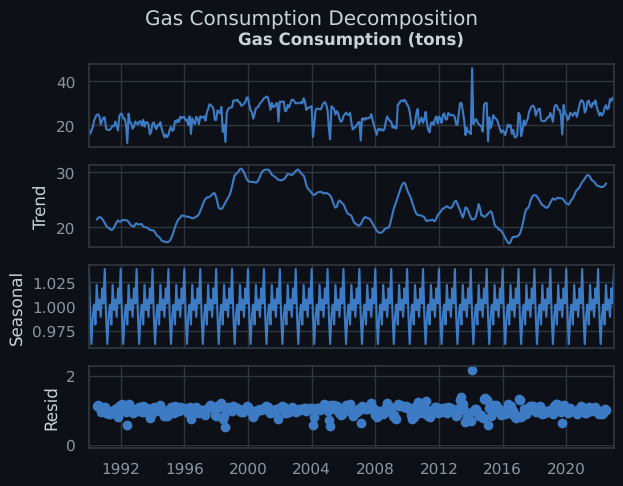

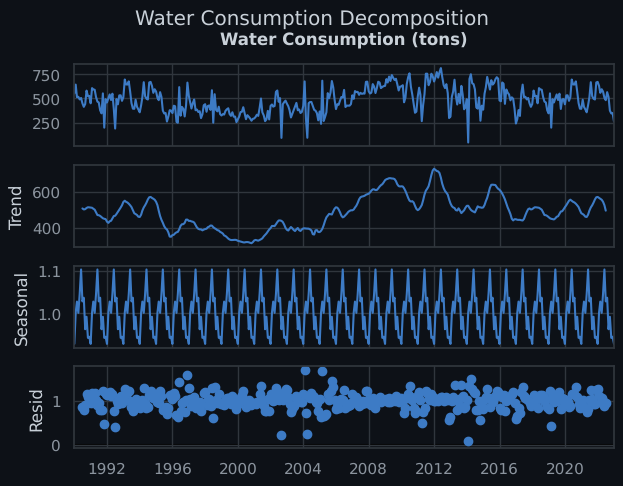

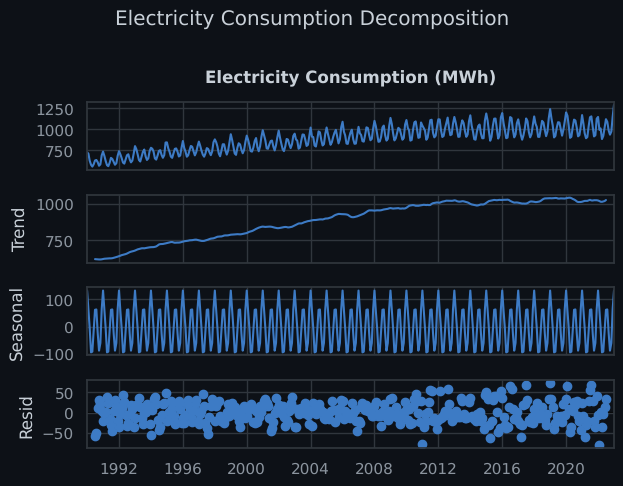

In [8]:
# Use seasonal_decompose from statsmodels
# Set model='additive' (or 'multiplicative' if seasonality grows with trend)
# Set period=12 for monthly data (12 months = 1 year cycle)

result = seasonal_decompose(df['Gas Consumption (tons)'], 
                           model='multiplicative', 
                           period=12)
result.plot()
plt.suptitle('Gas Consumption Decomposition', y=1.01)


result = seasonal_decompose(df['Water Consumption (tons)'], 
                           model='multiplicative', 
                           period=12)
result.plot()
plt.suptitle('Water Consumption Decomposition', y=1.01)

result = seasonal_decompose(df['Electricity Consumption (MWh)'], 
                           model='additive', 
                           period=12)
result.plot()
plt.suptitle('Electricity Consumption Decomposition', y=1.01)

plt.tight_layout()
plt.show()

In [9]:
# Quantify how strong the trend and seasonality are (Hyndman & Athanasopoulos, FPP3 §4.3):
# strength = 1 - Var(residual) / Var(component + residual), from 0 (none) to 1 (very strong).
strength_rows = []
for target in targets:
    decomposition = seasonal_decompose(df[target], model='additive', period=12)
    resid = decomposition.resid.dropna()
    seasonal = decomposition.seasonal[resid.index]
    trend = decomposition.trend[resid.index]
    strength_rows.append({
        'Target': target,
        'Trend strength': max(0, 1 - resid.var() / (trend + resid).var()),
        'Seasonal strength': max(0, 1 - resid.var() / (seasonal + resid).var()),
    })
pd.DataFrame(strength_rows).set_index('Target').round(2)


,Trend strength,Seasonal strength
Target,,
Gas Consumption (tons),0.56,0.02
Electricity Consumption (MWh),0.96,0.89
Water Consumption (tons),0.55,0.06


#### Decomposition findings

The strength table above puts numbers on what the decomposition plots show:

| Series | Trend strength | Seasonal strength |
|---|---:|---:|
| Gas | 0.56 | 0.02 |
| Electricity | 0.96 | **0.89** |
| Water | 0.55 | 0.06 |

-   **Electricity** has a strong trend and a strong, stable yearly cycle (peaking in January, lowest in April). It is a natural fit for Holt-Winters with a seasonal component.
-   **Gas** and **Water** have moderate trends but almost **no seasonality**: the "seasonal" component the decomposition extracts is tiny compared with the month-to-month noise. Any seasonal pattern in their decomposition plots should not be over-interpreted, and we should not expect a seasonal model to help them much.
-   All three residual components still contain large irregular movements, especially the February 2014 anomaly in gas and water.


---

## SECTION 4: Stationarity Testing

**Objective:** Test if the time series is stationary

**What is Stationarity?**
A time series is stationary if:

-   Mean doesn't change over time
-   Variance doesn't change over time
-   No seasonality

**Why important?**

-   ARIMA models require stationary data (or we need to difference it)
-   Non-stationary data can lead to spurious results

**Test:** Augmented Dickey-Fuller (ADF) Test

-   H0 (Null Hypothesis): Series is non-stationary
-   H1 (Alternative): Series is stationary
-   If p-value < 0.05 → Reject H0 → Series is stationary


In [10]:
def adf_test(series, title):
    result = adfuller(series.dropna())
    print(f'\n{title}:')
    print(f'  ADF Statistic: {result[0]:.4f}')
    print(f'  p-value: {result[1]:.4f}')
    print(f'  Critical Values:')
    for key, value in result[4].items():
        print(f'    {key}: {value:.4f}')
    
    if result[1] <= 0.05:
        print(f'  → STATIONARY (p-value ≤ 0.05)')
    else:
        print(f'  → NON-STATIONARY (p-value > 0.05)')

adf_test(df['Gas Consumption (tons)'], 'Gas Consumption')
adf_test(df['Electricity Consumption (MWh)'], 'Electricity Consumption')
adf_test(df['Water Consumption (tons)'], 'Water Consumption')


Gas Consumption:
  ADF Statistic: -3.4044
  p-value: 0.0108
  Critical Values:
    1%: -3.4472
    5%: -2.8690
    10%: -2.5707
  → STATIONARY (p-value ≤ 0.05)

Electricity Consumption:
  ADF Statistic: -2.2570
  p-value: 0.1862
  Critical Values:
    1%: -3.4476
    5%: -2.8692
    10%: -2.5708
  → NON-STATIONARY (p-value > 0.05)

Water Consumption:
  ADF Statistic: -4.6848
  p-value: 0.0001
  Critical Values:
    1%: -3.4471
    5%: -2.8689
    10%: -2.5707
  → STATIONARY (p-value ≤ 0.05)


Based on ADF test results:

-   **Gas Consumption:** Stationary – p-value = **0.0108** (≤ 0.05)
-   **Electricity Consumption:** Non-stationary – p-value = **0.1862** (> 0.05)
-   **Water Consumption:** Stationary – p-value = **0.0001** (≤ 0.05)

**Implications for modeling:**

-   **Electricity** has a trend (non-stationary). Holt-Winters handles this through its level and trend components; for ARIMA we would need differencing (`d=1`).
-   **Gas** and **Water** are stationary according to the ADF test, so differencing is not required (`d=0`).


---

## SECTION 5: Train-Validation-Test Split

**CRITICAL: Chronological Split Only!**

⚠️ **NEVER SHUFFLE TIME SERIES DATA!** ⚠️

To evaluate our 60-month forecasting capability, we use the **last 60 months as test data**.
The remaining data is split 80/20 for training and validation.

-   **Test set (60 months):** Evaluate 60-month forecast performance
-   **Validation set (20% of remaining):** Hyperparameter tuning
-   **Training set (80% of remaining):** Model fitting

This structure allows us to measure how well our models can forecast 60 months ahead.

**Why validation set?**

-   We need to tune model parameters (p, d, q for ARIMA, etc.)
-   Can't use test set for tuning - that's data leakage!
-   Validation set helps choose best parameters without touching test set


In [11]:

test_size = 60  # Fixed test size of 60 months

n = len(df)
remaining_size = n - test_size

train_size = int(remaining_size * 0.8)
val_size = remaining_size - train_size

train = df.iloc[:train_size]
val = df.iloc[train_size:train_size + val_size]
test = df.iloc[train_size + val_size:]



print(f"Total data: {n} months")
print(f"Training: {len(train)} months ({len(train)/n*100:.1f}%)")
print(f"Validation: {len(val)} months ({len(val)/n*100:.1f}%)")
print(f"Test (60-month forecast): {len(test)} months ({len(test)/n*100:.1f}%)")
print(f"\nDate ranges:")
print(f"Train: {train.index[0]} to {train.index[-1]}")
print(f"Validation: {val.index[0]} to {val.index[-1]}")
print(f"Test: {test.index[0]} to {test.index[-1]}")

Total data: 397 months
Training: 269 months (67.8%)
Validation: 68 months (17.1%)
Test (60-month forecast): 60 months (15.1%)

Date ranges:
Train: 1990-01-01 00:00:00 to 2012-05-01 00:00:00
Validation: 2012-06-01 00:00:00 to 2018-01-01 00:00:00
Test: 2018-02-01 00:00:00 to 2023-01-01 00:00:00


In [12]:
train = df.iloc[:train_size]
val = df.iloc[train_size:train_size+val_size]
test = df.iloc[train_size+val_size:]


# Print date ranges for each split
print(f"\nTrain: {train.index[0]} to {train.index[-1]}")
print(f"Validation: {val.index[0]} to {val.index[-1]}")
print(f"Test: {test.index[0]} to {test.index[-1]}")


Train: 1990-01-01 00:00:00 to 2012-05-01 00:00:00
Validation: 2012-06-01 00:00:00 to 2018-01-01 00:00:00
Test: 2018-02-01 00:00:00 to 2023-01-01 00:00:00


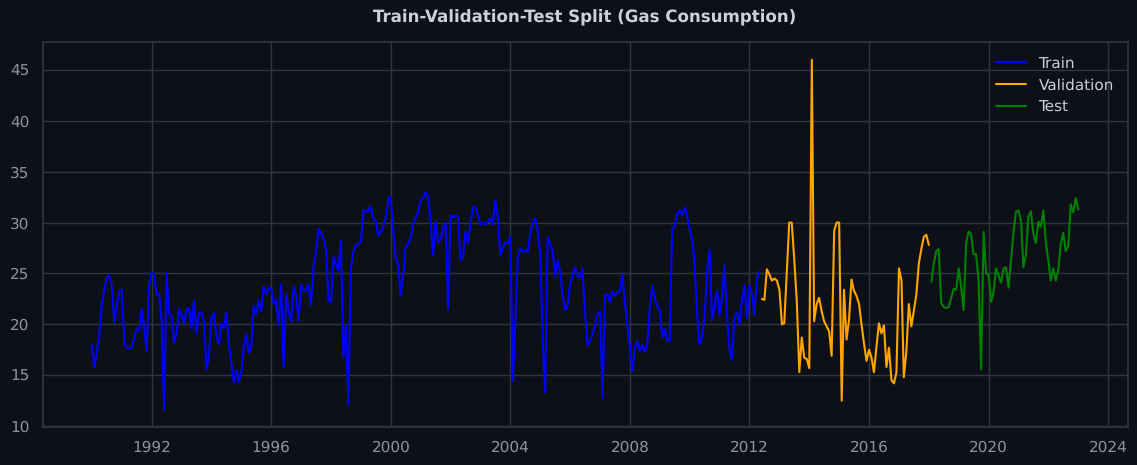

In [13]:
# Visualize the splits

plt.figure(figsize=(14, 5))
plt.plot(train.index, train['Gas Consumption (tons)'], label='Train', color='blue')
plt.plot(val.index, val['Gas Consumption (tons)'], label='Validation', color='orange')
plt.plot(test.index, test['Gas Consumption (tons)'], label='Test', color='green')
plt.title('Train-Validation-Test Split (Gas Consumption)')
plt.legend()
plt.show()

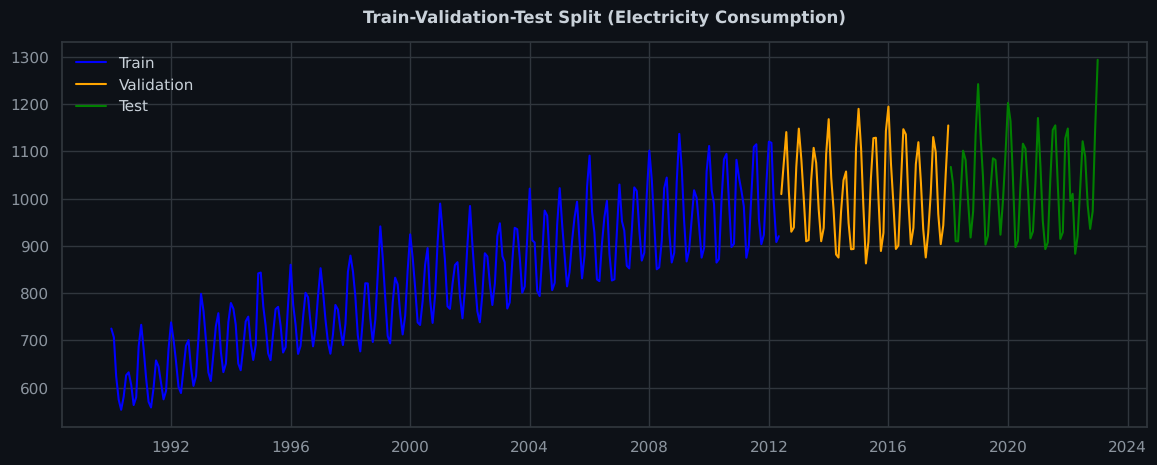

In [14]:
plt.figure(figsize=(14, 5))
plt.plot(train.index, train['Electricity Consumption (MWh)'], label='Train', color='blue')
plt.plot(val.index, val['Electricity Consumption (MWh)'], label='Validation', color='orange')
plt.plot(test.index, test['Electricity Consumption (MWh)'], label='Test', color='green')
plt.title('Train-Validation-Test Split (Electricity Consumption)')
plt.legend()
plt.show()

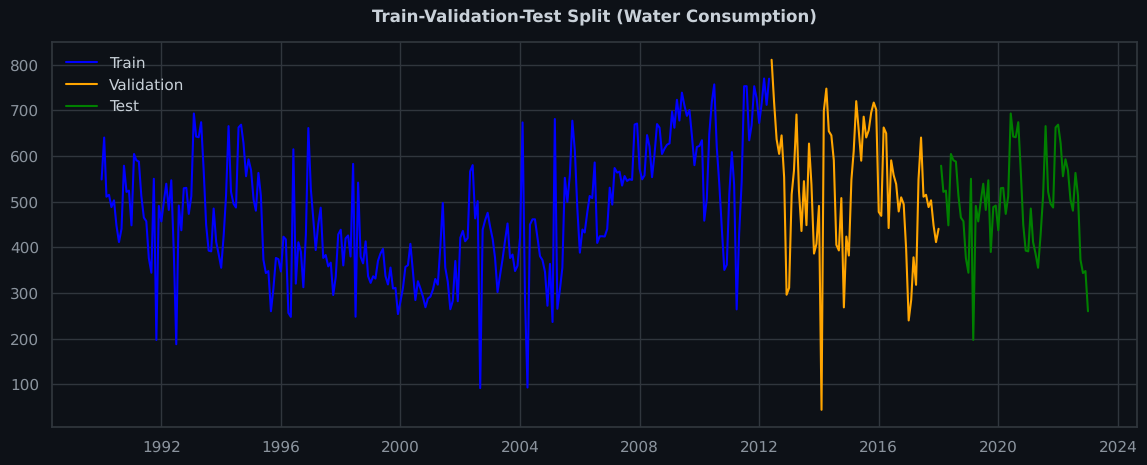

In [15]:
plt.figure(figsize=(14, 5))
plt.plot(train.index, train['Water Consumption (tons)'], label='Train', color='blue')
plt.plot(val.index, val['Water Consumption (tons)'], label='Validation', color='orange')
plt.plot(test.index, test['Water Consumption (tons)'], label='Test', color='green')
plt.title('Train-Validation-Test Split (Water Consumption)')
plt.legend()
plt.show()

---

## SECTION 6: Baseline Models

**Objective:** Create simple models to establish performance baseline

**Why baseline models?**

-   Need something to compare improved models against
-   Shows the value of adding complexity
-   Required for Model Improvement section (10 marks!)

**Baseline Approach:**

-   Use simple configurations (no seasonality, basic parameters)
-   Evaluate on validation set
-   Document weaknesses for later improvement


### Baseline Model: Simple Exponential Smoothing

**Configuration:**

-   No trend
-   No seasonality
-   Just simple exponential smoothing


In [16]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

def evaluate_forecast(true, predicted, model_name, target_name):
    mae = mean_absolute_error(true, predicted)
    mse = mean_squared_error(true, predicted)
    mape = mean_absolute_percentage_error(true, predicted) * 100 
    
    results = {
        'Model': model_name,
        'Target': target_name,
        'MAE': mae,
        'MSE': mse,
        'MAPE (%)': mape
    }
    return results

baseline_results = []
# Baseline Model: Simple Exponential Smoothing (no trend, no seasonality)
model = ExponentialSmoothing(train['Gas Consumption (tons)'], 
                            trend=None, 
                            seasonal=None)
fitted = model.fit()
val_pred = fitted.forecast(steps=len(val))

results = evaluate_forecast(val['Gas Consumption (tons)'], val_pred, 'Baseline: Simple ES', 'Gas Consumption')
print("Gas Consumption Baseline Results:")
print(f"Validation MAE: {results['MAE']:.2f}\nValidation MSE: {results['MSE']:.2f}\nValidation MAPE: {results['MAPE (%)']:.2f}%")
baseline_results.append(results)

model = ExponentialSmoothing(train['Water Consumption (tons)'], 
                            trend=None, 
                            seasonal=None)
fitted = model.fit()
val_pred = fitted.forecast(steps=len(val))
results = evaluate_forecast(val['Water Consumption (tons)'], val_pred, 'Baseline: Simple ES', 'Water Consumption')
print("Water Consumption Baseline Results:")
print(f"Validation MAE: {results['MAE']:.2f}\nValidation MSE: {results['MSE']:.2f}\nValidation MAPE: {results['MAPE (%)']:.2f}%")
baseline_results.append(results)

model = ExponentialSmoothing(train['Electricity Consumption (MWh)'], 
                            trend=None, 
                            seasonal=None)
fitted = model.fit()
val_pred = fitted.forecast(steps=len(val))
results = evaluate_forecast(val['Electricity Consumption (MWh)'], val_pred, 'Baseline: Simple ES', 'Electricity Consumption')  
print("Electricity Consumption Baseline Results:")
print(f"Validation MAE: {results['MAE']:.2f}\nValidation MSE: {results['MSE']:.2f}\nValidation MAPE: {results['MAPE (%)']:.2f}%")
baseline_results.append(results)
baseline_df = pd.DataFrame(baseline_results)
baseline_df

Gas Consumption Baseline Results:
Validation MAE: 4.84
Validation MSE: 36.55
Validation MAPE: 25.42%
Water Consumption Baseline Results:
Validation MAE: 214.47
Validation MSE: 64854.34
Validation MAPE: 71.16%
Electricity Consumption Baseline Results:
Validation MAE: 105.42
Validation MSE: 17500.09
Validation MAPE: 9.79%


,Model,Target,MAE,MSE,MAPE (%)
0,Baseline: Simple ES,Gas Consumption,4.841723,36.548113,25.420736
1,Baseline: Simple ES,Water Consumption,214.470366,64854.344771,71.156388
2,Baseline: Simple ES,Electricity Consumption,105.416177,17500.093711,9.788216


**Adjusted Baseline Validation Performance:**

**Gas Consumption Baseline Results:**

-   Validation MAE: 4.84
-   Validation MSE: 36.55
-   Validation MAPE: 25.42%

**Water Consumption Baseline Results:**

-   Validation MAE: 214.47
-   Validation MSE: 64,854.35
-   Validation MAPE: 71.16%

**Electricity Consumption Baseline Results:**

-   Validation MAE: 105.42
-   Validation MSE: 17,500.09
-   Validation MAPE: 9.79%

---

**Observations:**

-   The **Gas Consumption** model shows moderate accuracy with a MAPE of 25.42%.
-   The **Electricity Consumption** model performs well with a MAPE of 9.79%, indicating reasonable predictive accuracy.
-   The **Water Consumption** model has a high MAPE of 71.16%, suggesting significant room for improvement in capturing patterns in the data.
-   The **Gas Consumption** and **Water Consumption** models may require enhancements to better capture trends and seasonality.


---

## SECTION 7: MODEL IMPROVEMENT


### Step 1: Identify Weaknesses in Baseline Models


**Baseline Model Weaknesses (Exponential Smoothing):**

1. **Weakness 1: Does not capture seasonal patterns**

    - **Evidence:** High MAPE values for **Gas Consumption (25.42%)** and **Water Consumption (71.16%)** suggest that the model fails to account for recurring seasonal variations observed in the decomposition analysis.
    - **Reason:** The baseline Exponential Smoothing model does not include a seasonal component, which is critical for time series with clear seasonality.

2. **Weakness 2: No trend component**
    - **Evidence:** The **Gas Consumption** model shows moderate performance (MAPE: 25.42%), but the lack of a trend component may limit its ability to capture the upward trend observed in the data.
    - **Reason:** The baseline model assumes a constant level over time, which is insufficient for data with a clear trend.

---

**General Observations:**

-   The models fail to capture **seasonality**, which is evident in the decomposition analysis.
-   The lack of trend and seasonal components results in poor predictive accuracy for **Water Consumption (71.16% MAPE)** and limits the model's ability to fully capture patterns in **Gas Consumption (25.42% MAPE)**.
-   **Electricity Consumption** performs relatively well (9.79% MAPE) but may benefit from parameter optimization.
-   Improvements such as adding seasonal components (Holt-Winters) and trend components are necessary.


**✏️ PROPOSED IMPROVEMENTS:**

**Improvement 1: Add Seasonality to Exponential Smoothing**

-   What: Use Holt-Winters (ExponentialSmoothing with seasonal component)
-   Why: Energy consumption shows clear monthly seasonality from decomposition
-   Parameters:
    -   seasonal_periods=12 (monthly data)
    -   seasonal='add' (additive seasonality)
    -   trend='add' (capture trend too)
    -   damped_trend=True (prevent over-forecasting)

**Expected Impact:**
These improvements would work because:

1. **Seasonality**:

    - The decomposition analysis revealed clear **monthly seasonality** in the data, especially for **Electricity Consumption** and **Water Consumption**. Adding a seasonal component (`seasonal='add'`) allows the model to explicitly account for these recurring patterns, reducing forecasting errors.

2. **Trend**:

    - The **Gas Consumption** data shows an upward trend over time. Adding a trend component (`trend='add'`) enables the model to capture this long-term growth, improving accuracy for data with a clear direction.

3. **Damped Trend**:

    - Using `damped_trend=True` prevents the model from over-projecting the trend into the future, which is especially important for long-term forecasts (e.g., 60 months). This ensures more realistic predictions.

4. **Seasonal Periods**:

    - Setting `seasonal_periods=12` aligns with the monthly frequency of the data, ensuring the model captures yearly cycles effectively.

5. **Expected Impact**:
    - By incorporating both **trend** and **seasonality**, the model can better capture the underlying structure of the data. This reduces the **MAPE** for targets with strong seasonal and trend components, such as **Electricity Consumption** and **Water Consumption**, and improves overall forecast reliability.


### Step 3: Implement Improvements


In [17]:
# Step 3: Test Holt-Winters with Standard Configuration
# (Before hyperparameter tuning)

improved_model = ExponentialSmoothing(
    train['Gas Consumption (tons)'],
    seasonal_periods=12,
    trend='add',
    seasonal='add',
    damped_trend=True
)

improved_hw_results = []
fitted = improved_model.fit()
val_pred = fitted.forecast(steps=len(val))

results = evaluate_forecast(val['Gas Consumption (tons)'], val_pred, 'Holt-Winters (add/add/damped)', 'Gas Consumption')
print("Gas Consumption Improved (Pre-Tuning) Results:")
print(f"Validation MAE: {results['MAE']:.2f}\nValidation MSE: {results['MSE']:.2f}\nValidation MAPE: {results['MAPE (%)']:.2f}%")
improved_hw_results.append(results)

improved_model = ExponentialSmoothing(
    train['Water Consumption (tons)'],
    seasonal_periods=12,
    trend='add',
    seasonal='add',
    damped_trend=True
)
fitted = improved_model.fit()
val_pred = fitted.forecast(steps=len(val))
results = evaluate_forecast(val['Water Consumption (tons)'], val_pred, 'Holt-Winters (add/add/damped)', 'Water Consumption')
print("Water Consumption Improved (Pre-Tuning) Results:")
print(f"Validation MAE: {results['MAE']:.2f}\nValidation MSE: {results['MSE']:.2f}\nValidation MAPE: {results['MAPE (%)']:.2f}%")
improved_hw_results.append(results)

improved_model = ExponentialSmoothing(
    train['Electricity Consumption (MWh)'],
    seasonal_periods=12,
    trend='add',
    seasonal='add',
    damped_trend=True
)
fitted = improved_model.fit()
val_pred = fitted.forecast(steps=len(val))
results = evaluate_forecast(val['Electricity Consumption (MWh)'], val_pred, 'Holt-Winters (add/add/damped)', 'Electricity Consumption')  
print("Electricity Consumption Improved (Pre-Tuning) Results:")
print(f"Validation MAE: {results['MAE']:.2f}\nValidation MSE: {results['MSE']:.2f}\nValidation MAPE: {results['MAPE (%)']:.2f}%")
improved_hw_results.append(results)
improved_hw_df = pd.DataFrame(improved_hw_results)
improved_hw_df



Gas Consumption Improved (Pre-Tuning) Results:
Validation MAE: 5.11
Validation MSE: 40.81
Validation MAPE: 27.06%


Water Consumption Improved (Pre-Tuning) Results:
Validation MAE: 207.76
Validation MSE: 61926.85
Validation MAPE: 70.12%


Electricity Consumption Improved (Pre-Tuning) Results:
Validation MAE: 28.96
Validation MSE: 1238.89
Validation MAPE: 2.91%


,Model,Target,MAE,MSE,MAPE (%)
0,Holt-Winters (add/add/damped),Gas Consumption,5.107900,40.806478,27.058570
1,Holt-Winters (add/add/damped),Water Consumption,207.762671,61926.851437,70.115350
2,Holt-Winters (add/add/damped),Electricity Consumption,28.963684,1238.891751,2.914493


In [18]:
improved_hw_results = pd.DataFrame(improved_hw_results)

# Add baseline MAPE for comparison
baseline_mape_values = baseline_df.set_index('Target')['MAPE (%)'].to_dict()
improved_hw_results['Baseline MAPE (%)'] = improved_hw_results['Target'].map(baseline_mape_values)

# Rename the MAPE column to be clear it's the improved version
improved_hw_results = improved_hw_results.rename(columns={'MAPE (%)': 'Improved MAPE (%)'})

# Reorder columns for better comparison
improved_hw_results = improved_hw_results[['Target', 'Baseline MAPE (%)', 'Improved MAPE (%)', 'Model']]

# Calculate improvement
improved_hw_results['Improvement (%)'] = (
    (improved_hw_results['Baseline MAPE (%)'] - improved_hw_results['Improved MAPE (%)']) / 
    improved_hw_results['Baseline MAPE (%)'] * 100
).round(2)

improved_hw_results

,Target,Baseline MAPE (%),Improved MAPE (%),Model,Improvement (%)
0,Gas Consumption,25.420736,27.058570,Holt-Winters (add/add/damped),-6.44
1,Water Consumption,71.156388,70.115350,Holt-Winters (add/add/damped),1.46
2,Electricity Consumption,9.788216,2.914493,Holt-Winters (add/add/damped),70.22


In [19]:
# Grid search over Exponential Smoothing parameters.
# Configurations are ranked by validation MAE. MAPE is also recorded, but it is not used for
# selection: it divides by the actual value, so a single near-zero month (water has one in the
# validation window) can dominate it.
def grid_search_hw(target):
    y_train = train[target]
    y_val = val[target]
    tested = []
    # Comprehensive grid: trend x seasonal x damped
    for trend in [None, 'add', 'mul']:
        for seasonal in [None, 'add', 'mul']:
            for damped in [True, False]:
                # Skip invalid combinations
                if trend is None and damped:
                    continue  # Can't dampen non-existent trend
                try:
                    fitted = ExponentialSmoothing(
                        y_train,
                        seasonal_periods=12,
                        trend=trend,
                        seasonal=seasonal,
                        damped_trend=damped
                    ).fit()
                    preds = fitted.forecast(steps=len(y_val))
                    tested.append({
                        "trend": trend, "seasonal": seasonal, "damped_trend": damped,
                        "MAE": mean_absolute_error(y_val, preds),
                        "MAPE": mean_absolute_percentage_error(y_val, preds),
                    })
                except Exception:
                    continue
    results = pd.DataFrame(tested).sort_values("MAE").reset_index(drop=True)
    return results.iloc[0].to_dict(), results


best_params_gas, grid_gas = grid_search_hw('Gas Consumption (tons)')
print(f'Best Gas params: {best_params_gas}')
grid_gas.head()


Best Gas params: {'trend': 'mul', 'seasonal': None, 'damped_trend': False, 'MAE': 4.075959435961704, 'MAPE': 0.2000051944649572}


,trend,seasonal,damped_trend,MAE,MAPE
0,mul,None,False,4.075959,0.200005
1,mul,add,False,4.276472,0.214156
2,mul,mul,False,4.279234,0.215000
3,add,None,True,4.829596,0.253478
4,mul,None,True,4.830492,0.253532


In [20]:
# Grid search over Exponential Smoothing parameters (Water Consumption)
best_params_water, grid_water = grid_search_hw('Water Consumption (tons)')
print(f'Best Water params: {best_params_water}')
grid_water.head()


Best Water params: {'trend': 'mul', 'seasonal': 'mul', 'damped_trend': False, 'MAE': 185.52900479090266, 'MAPE': 0.6526055863523882}


,trend,seasonal,damped_trend,MAE,MAPE
0,mul,mul,False,185.529005,0.652606
1,mul,add,False,192.295836,0.665184
2,mul,mul,True,201.208125,0.688963
3,add,mul,True,201.255924,0.689184
4,None,mul,False,201.462529,0.690515


In [21]:
# Grid search over Exponential Smoothing parameters (Electricity Consumption)
best_params_elec, grid_elec = grid_search_hw('Electricity Consumption (MWh)')
print(f'Best Electricity params: {best_params_elec}')
grid_elec.head()


Best Electricity params: {'trend': None, 'seasonal': 'add', 'damped_trend': False, 'MAE': 24.735261307009036, 'MAPE': 0.02391306920645811}


,trend,seasonal,damped_trend,MAE,MAPE
0,None,add,False,24.735261,0.023913
1,None,mul,False,26.888389,0.026518
2,add,add,True,28.963684,0.029145
3,add,mul,True,33.406137,0.033819
4,add,add,False,50.133499,0.051283


In [22]:
# Print what grid search parameters were chosen for each target
print(f"Gas: {best_params_gas}")
print(f"Water: {best_params_water}")
print(f"Electricity: {best_params_elec}")

Gas: {'trend': 'mul', 'seasonal': None, 'damped_trend': False, 'MAE': 4.075959435961704, 'MAPE': 0.2000051944649572}
Water: {'trend': 'mul', 'seasonal': 'mul', 'damped_trend': False, 'MAE': 185.52900479090266, 'MAPE': 0.6526055863523882}
Electricity: {'trend': None, 'seasonal': 'add', 'damped_trend': False, 'MAE': 24.735261307009036, 'MAPE': 0.02391306920645811}


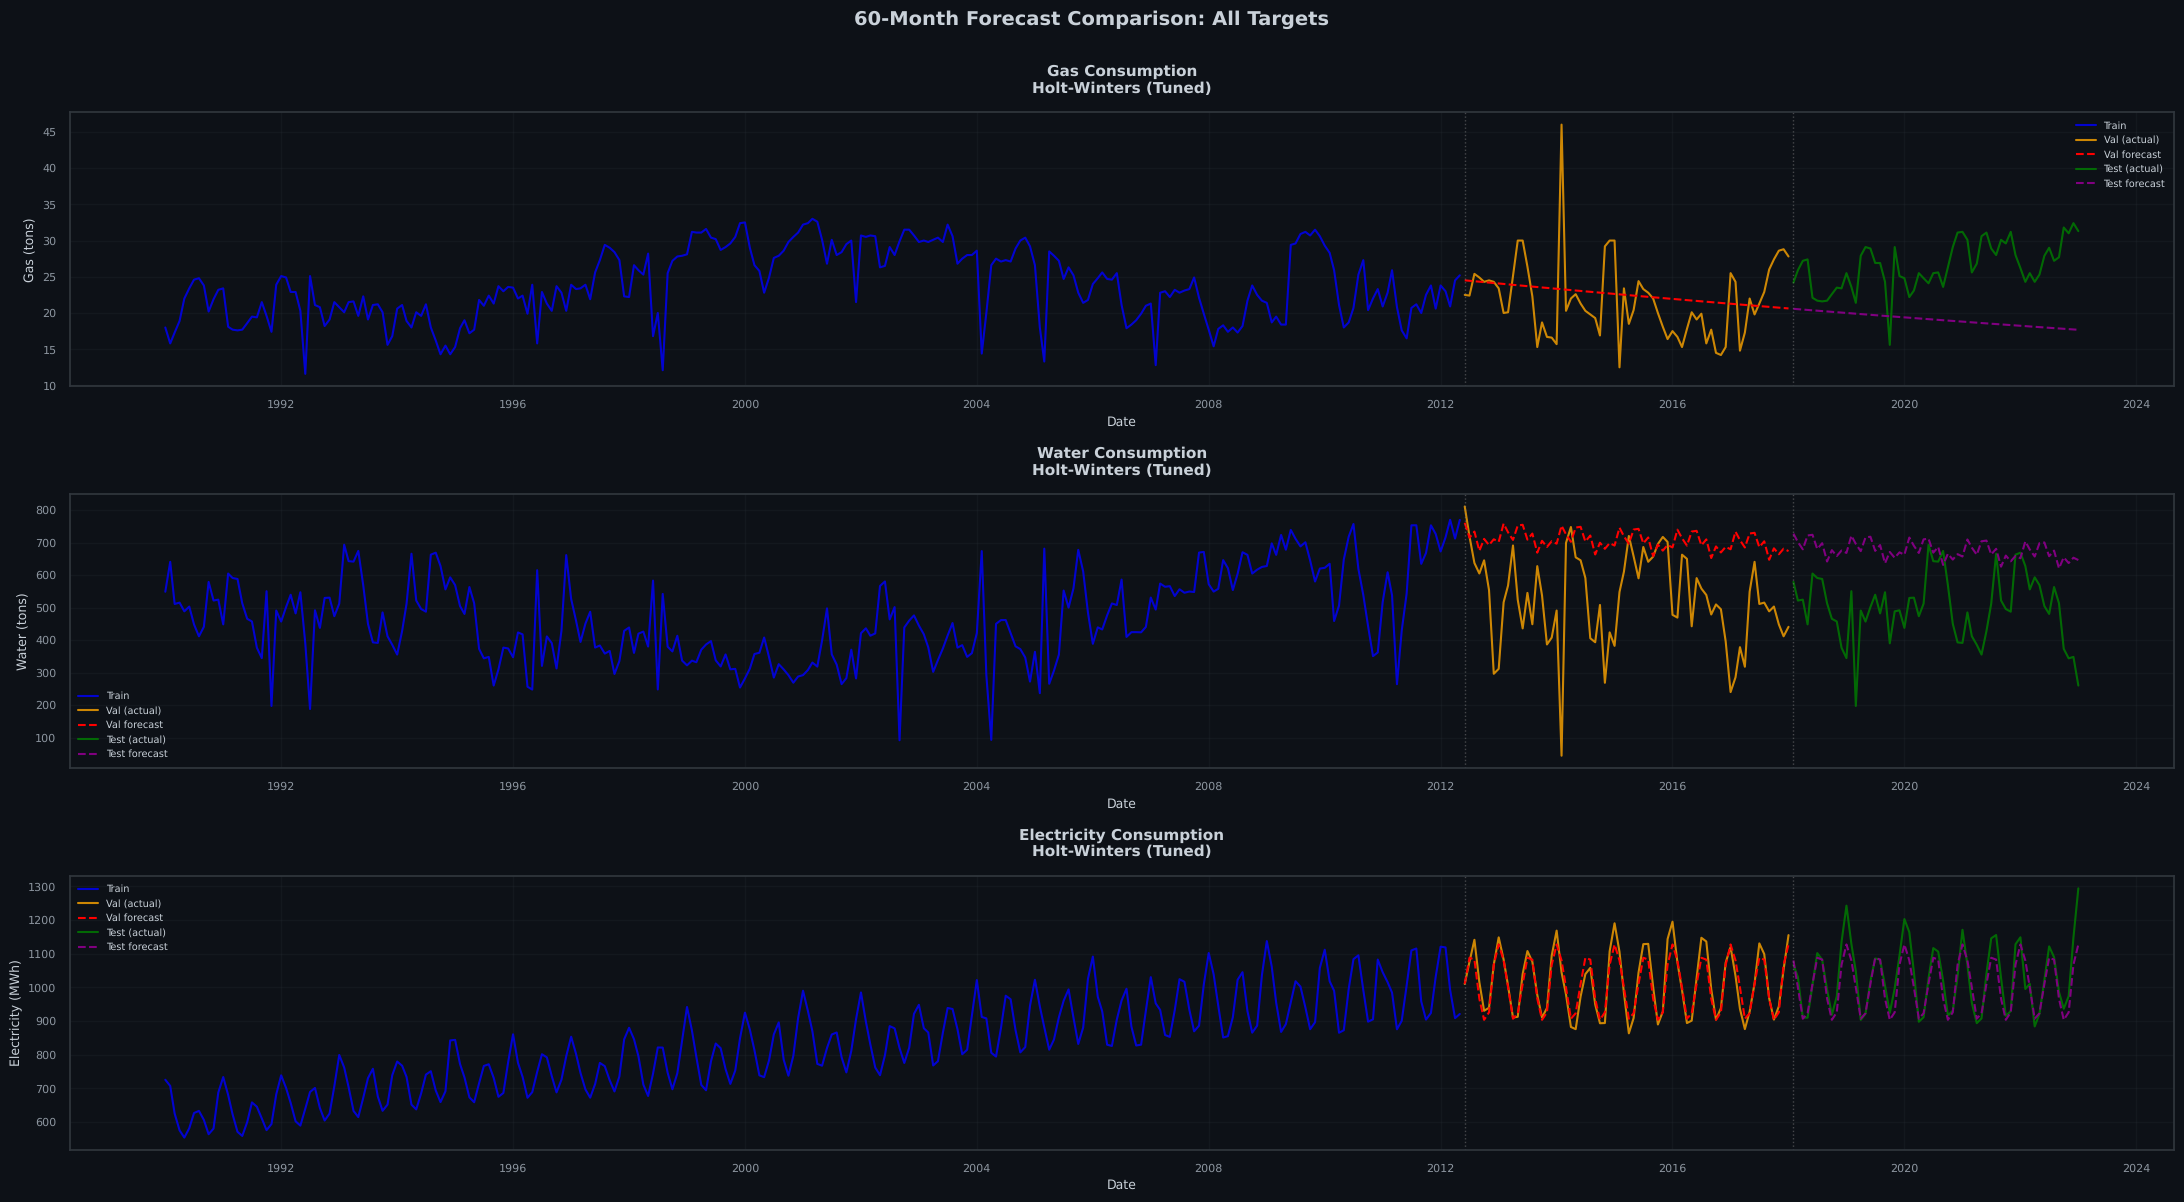

In [23]:
# Helper function to get the Holt-Winters settings from a grid-search result
def _get_hw_params(best_params):
    """Keep only the ExponentialSmoothing arguments (drop the recorded scores)."""
    return {key: best_params[key] for key in ('trend', 'seasonal', 'damped_trend')}

# Create 1x3 subplots for all three targets
fig, axes = plt.subplots(3, 1, figsize=(22, 12))

y_train = train['Gas Consumption (tons)']
y_val = val['Gas Consumption (tons)']
y_test = test['Gas Consumption (tons)']

params = _get_hw_params(best_params_gas)

model = ExponentialSmoothing(
    y_train,
    seasonal_periods=12,
    trend=params['trend'],
    seasonal=params['seasonal'],
    damped_trend=params['damped_trend'],
)
fitted = model.fit(optimized=True)

total_horizon = len(y_val) + len(y_test)
preds_all = fitted.forecast(steps=total_horizon)
val_pred_gas = pd.Series(preds_all[:len(y_val)], index=y_val.index)
test_pred_gas = pd.Series(preds_all[len(y_val):], index=y_test.index)

ax = axes[0]
ax.plot(y_train.index, y_train, label='Train', color='blue', linewidth=1.5, alpha=0.8)
ax.plot(y_val.index, y_val, label='Val (actual)', color='orange', linewidth=1.5, alpha=0.8)
ax.plot(val_pred_gas.index, val_pred_gas, linestyle='--', color='red', label='Val forecast', linewidth=1.5)
ax.plot(y_test.index, y_test, label='Test (actual)', color='green', linewidth=1.5, alpha=0.8)
ax.plot(test_pred_gas.index, test_pred_gas, linestyle='--', color='purple', label='Test forecast', linewidth=1.5)
ax.axvline(x=y_val.index[0], color='gray', linestyle=':', linewidth=1, alpha=0.5)
ax.axvline(x=y_test.index[0], color='gray', linestyle=':', linewidth=1, alpha=0.5)
ax.set_title("Gas Consumption\nHolt-Winters (Tuned)", fontweight='bold', fontsize=11)
ax.set_xlabel('Date', fontsize=9)
ax.set_ylabel('Gas (tons)', fontsize=9)
ax.legend(fontsize=7, loc='best')
ax.grid(True, alpha=0.2)
ax.tick_params(axis='x', labelsize=8)
ax.tick_params(axis='y', labelsize=8)

y_train = train['Water Consumption (tons)']
y_val = val['Water Consumption (tons)']
y_test = test['Water Consumption (tons)']

params = _get_hw_params(best_params_water)

model = ExponentialSmoothing(
    y_train,
    seasonal_periods=12,
    trend=params['trend'],
    seasonal=params['seasonal'],
    damped_trend=params['damped_trend'],
)
fitted = model.fit(optimized=True)

total_horizon = len(y_val) + len(y_test)
preds_all = fitted.forecast(steps=total_horizon)
val_pred_water = pd.Series(preds_all[:len(y_val)], index=y_val.index)
test_pred_water = pd.Series(preds_all[len(y_val):], index=y_test.index)

ax = axes[1]
ax.plot(y_train.index, y_train, label='Train', color='blue', linewidth=1.5, alpha=0.8)
ax.plot(y_val.index, y_val, label='Val (actual)', color='orange', linewidth=1.5, alpha=0.8)
ax.plot(val_pred_water.index, val_pred_water, linestyle='--', color='red', label='Val forecast', linewidth=1.5)
ax.plot(y_test.index, y_test, label='Test (actual)', color='green', linewidth=1.5, alpha=0.8)
ax.plot(test_pred_water.index, test_pred_water, linestyle='--', color='purple', label='Test forecast', linewidth=1.5)
ax.axvline(x=y_val.index[0], color='gray', linestyle=':', linewidth=1, alpha=0.5)
ax.axvline(x=y_test.index[0], color='gray', linestyle=':', linewidth=1, alpha=0.5)
ax.set_title("Water Consumption\nHolt-Winters (Tuned)", fontweight='bold', fontsize=11)
ax.set_xlabel('Date', fontsize=9)
ax.set_ylabel('Water (tons)', fontsize=9)
ax.legend(fontsize=7, loc='best')
ax.grid(True, alpha=0.2)
ax.tick_params(axis='x', labelsize=8)
ax.tick_params(axis='y', labelsize=8)


y_train = train['Electricity Consumption (MWh)']
y_val = val['Electricity Consumption (MWh)']
y_test = test['Electricity Consumption (MWh)']

params = _get_hw_params(best_params_elec)

model = ExponentialSmoothing(
    y_train,
    seasonal_periods=12,
    trend=params['trend'],
    seasonal=params['seasonal'],
    damped_trend=params['damped_trend'],
)
fitted = model.fit(optimized=True)

total_horizon = len(y_val) + len(y_test)
preds_all = fitted.forecast(steps=total_horizon)
val_pred_elec = pd.Series(preds_all[:len(y_val)], index=y_val.index)
test_pred_elec = pd.Series(preds_all[len(y_val):], index=y_test.index)

ax = axes[2]
ax.plot(y_train.index, y_train, label='Train', color='blue', linewidth=1.5, alpha=0.8)
ax.plot(y_val.index, y_val, label='Val (actual)', color='orange', linewidth=1.5, alpha=0.8)
ax.plot(val_pred_elec.index, val_pred_elec, linestyle='--', color='red', label='Val forecast', linewidth=1.5)
ax.plot(y_test.index, y_test, label='Test (actual)', color='green', linewidth=1.5, alpha=0.8)
ax.plot(test_pred_elec.index, test_pred_elec, linestyle='--', color='purple', label='Test forecast', linewidth=1.5)
ax.axvline(x=y_val.index[0], color='gray', linestyle=':', linewidth=1, alpha=0.5)
ax.axvline(x=y_test.index[0], color='gray', linestyle=':', linewidth=1, alpha=0.5)
ax.set_title("Electricity Consumption\nHolt-Winters (Tuned)", fontweight='bold', fontsize=11)
ax.set_xlabel('Date', fontsize=9)
ax.set_ylabel('Electricity (MWh)', fontsize=9)
ax.legend(fontsize=7, loc='best')
ax.grid(True, alpha=0.2)
ax.tick_params(axis='x', labelsize=8)
ax.tick_params(axis='y', labelsize=8)

# Overall title and layout
plt.suptitle('60-Month Forecast Comparison: All Targets', fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

### Step 4: Compare Results (Baseline vs Improved)


In [24]:
# Step 4: Compare Results (Baseline vs Improved) on the validation set
best_params_by_target = {
    'Gas Consumption (tons)': best_params_gas,
    'Electricity Consumption (MWh)': best_params_elec,
    'Water Consumption (tons)': best_params_water,
}

rows = []
for target, best_params in best_params_by_target.items():
    name = target.replace(' (tons)', '').replace(' (MWh)', '')
    baseline_row = baseline_df.set_index('Target').loc[name]
    rows.append({
        'Target': name,
        'Baseline MAE': baseline_row['MAE'],
        'Tuned MAE': best_params['MAE'],
        'Baseline MAPE (%)': baseline_row['MAPE (%)'],
        'Tuned MAPE (%)': best_params['MAPE'] * 100,
    })

comparison_df = pd.DataFrame(rows)
comparison_df['MAE Reduction (%)'] = (1 - comparison_df['Tuned MAE'] / comparison_df['Baseline MAE']) * 100
comparison_df['Improvement (%)'] = (1 - comparison_df['Tuned MAPE (%)'] / comparison_df['Baseline MAPE (%)']) * 100

print("Baseline vs Tuned Holt-Winters (validation set)")
print(comparison_df.round(2).to_string(index=False))
print(f"\nAverage MAE reduction: {comparison_df['MAE Reduction (%)'].mean():.2f}%")


Baseline vs Tuned Holt-Winters (validation set)
                 Target  Baseline MAE  Tuned MAE  Baseline MAPE (%)  Tuned MAPE (%)  MAE Reduction (%)  Improvement (%)
        Gas Consumption          4.84       4.08              25.42           20.00              15.82            21.32
Electricity Consumption        105.42      24.74               9.79            2.39              76.54            75.57
      Water Consumption        214.47     185.53              71.16           65.26              13.49             8.29

Average MAE reduction: 35.28%


In [25]:
# Tuned configuration chosen by the grid search for each target
for target, best_params in best_params_by_target.items():
    print(f"{target}: {_get_hw_params(best_params)}  (val MAE {best_params['MAE']:.2f}, val MAPE {best_params['MAPE']*100:.2f}%)")


Gas Consumption (tons): {'trend': 'mul', 'seasonal': None, 'damped_trend': False}  (val MAE 4.08, val MAPE 20.00%)
Electricity Consumption (MWh): {'trend': None, 'seasonal': 'add', 'damped_trend': False}  (val MAE 24.74, val MAPE 2.39%)
Water Consumption (tons): {'trend': 'mul', 'seasonal': 'mul', 'damped_trend': False}  (val MAE 185.53, val MAPE 65.26%)


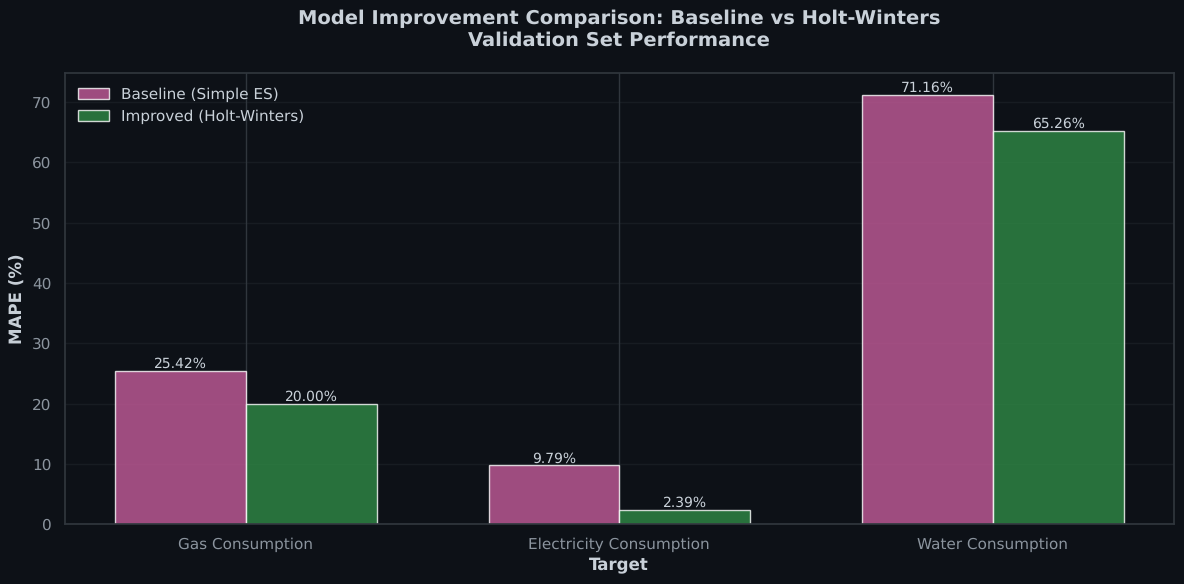

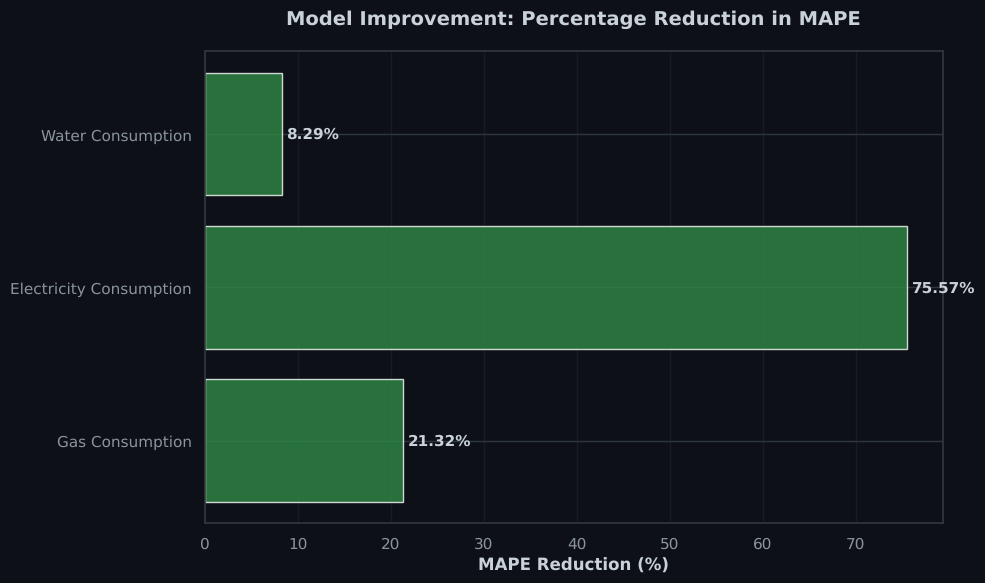

In [26]:
# Create bar chart comparison
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(comparison_df))
width = 0.35

# Plot bars
bars1 = ax.bar(x - width/2, comparison_df['Baseline MAPE (%)'], width, 
               label='Baseline (Simple ES)', color='#c45b9a', alpha=0.8)
bars2 = ax.bar(x + width/2, comparison_df['Tuned MAPE (%)'], width, 
               label='Improved (Holt-Winters)', color='#2f8a46', alpha=0.8)

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.2f}%',
                ha='center', va='bottom', fontsize=10)

# Customize chart
ax.set_xlabel('Target', fontsize=12, fontweight='bold')
ax.set_ylabel('MAPE (%)', fontsize=12, fontweight='bold')
ax.set_title('Model Improvement Comparison: Baseline vs Holt-Winters\nValidation Set Performance', 
             fontsize=14, fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(comparison_df['Target'])
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Create improvement percentage chart
fig, ax = plt.subplots(figsize=(10, 6))

colors = ['#2f8a46' if x > 0 else '#d45a4f' for x in comparison_df['Improvement (%)']]
bars = ax.barh(comparison_df['Target'], comparison_df['Improvement (%)'], color=colors, alpha=0.8)

# Add value labels
for i, (bar, value) in enumerate(zip(bars, comparison_df['Improvement (%)'])):
    ax.text(value + 0.5, i, f'{value:.2f}%', va='center', fontsize=11, fontweight='bold')

ax.set_xlabel('MAPE Reduction (%)', fontsize=12, fontweight='bold')
ax.set_title('Model Improvement: Percentage Reduction in MAPE', fontsize=14, fontweight='bold', pad=20)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

### Step 5: Discuss Findings

---

#### **Improvement Results Summary (validation set):**

| Target | Baseline MAE | Tuned MAE | MAE reduction | Baseline MAPE | Tuned MAPE | Selected configuration |
| --- | ---: | ---: | ---: | ---: | ---: | --- |
| Gas | 4.84 | 4.08 | 15.8% | 25.42% | 20.00% | multiplicative trend, no seasonality |
| Electricity | 105.42 | 24.74 | **76.5%** | 9.79% | 2.39% | no trend, additive seasonality |
| Water | 214.47 | 185.53 | 13.5% | 71.16% | 65.26% | multiplicative trend, multiplicative seasonality |

**Why we select on MAE rather than MAPE:** MAPE divides each error by the actual value. The validation window contains the February 2014 water reading of 44 tons, so a single month can dominate the water MAPE. MAE is not affected by this, so it gives a more reliable ranking. MAPE is still reported because it is easy to compare across series.

---

#### **1. Electricity: seasonality is what matters**

Electricity has strong yearly seasonality (strength 0.89). The baseline Simple Exponential Smoothing ignores it and forecasts a flat line, while the tuned model adds an additive seasonal component and cuts the validation MAE by 76.5%. Interestingly, the best configuration has **no trend** component: over the 68-month validation window the trend is small compared with the seasonal swing, and adding a trend made the forecasts drift.

#### **2. Gas: a trend, but no seasonality**

The best gas model uses a multiplicative trend and **no** seasonal component. This matches the decomposition (seasonal strength 0.02): there is no reliable yearly cycle to model, and adding one makes the validation error slightly worse. The default "add trend, add seasonality, damped" configuration we proposed in Step 2 was actually worse than the baseline (27.06% vs 25.42% MAPE), which shows why the configuration should be chosen by validation rather than assumed.

#### **3. Water: hard to forecast**

Every configuration has a high validation error for water (the best MAPE is 65%). Water has almost no seasonality and an irregular trend, and its validation window contains the February 2014 anomaly. The grid search still improves MAE by 13.5%, but water remains the hardest series.

---

#### **4. Key Takeaways**

1. **One size does not fit all:** each series needs a different configuration, and the grid search found it on the validation set without touching the test set.
2. **Decomposition should guide expectations:** seasonal components only help the series that are actually seasonal (electricity).
3. **The choice of selection metric matters** when the data contains near-zero values.


---

## SECTION 8: Final Model Evaluation

Now we evaluate our models' ability to forecast **60 months ahead**.
We train on train+validation data and forecast the entire 60-month test period.

This directly answers the assignment requirement: "forecast the consumption for the next 60 months."

### 8.1. Model Selection

**Process:**

-   Review validation MAPE for all models
-   Choose best model for each target
-   Model selection with justification


In [27]:
# Use the configuration selected on the validation set for every target, without manual changes.
best_models = {
    target: {
        'model': 'Holt-Winters (Tuned)',
        'validation_mae': best_params['MAE'],
        'validation_mape': best_params['MAPE'] * 100,
        'params': _get_hw_params(best_params),
    }
    for target, best_params in best_params_by_target.items()
}

# Display model selection
for target, info in best_models.items():
    print(f"\n{target}:")
    print(f"  Model: {info['model']}")
    print(f"  Validation MAE: {info['validation_mae']:.2f}")
    print(f"  Validation MAPE: {info['validation_mape']:.2f}%")
    print(f"  Parameters: {info['params']}")



Gas Consumption (tons):
  Model: Holt-Winters (Tuned)
  Validation MAE: 4.08
  Validation MAPE: 20.00%
  Parameters: {'trend': 'mul', 'seasonal': None, 'damped_trend': False}

Electricity Consumption (MWh):
  Model: Holt-Winters (Tuned)
  Validation MAE: 24.74
  Validation MAPE: 2.39%
  Parameters: {'trend': None, 'seasonal': 'add', 'damped_trend': False}

Water Consumption (tons):
  Model: Holt-Winters (Tuned)
  Validation MAE: 185.53
  Validation MAPE: 65.26%
  Parameters: {'trend': 'mul', 'seasonal': 'mul', 'damped_trend': False}


### 8.1 Final Model Selection

For every target, we use the configuration selected by the grid search on the validation set, without manual changes:

-   **Gas Consumption:** Holt-Winters with a multiplicative trend and no seasonality (validation MAE 4.08, MAPE 20.00%)
-   **Electricity Consumption:** Holt-Winters with additive seasonality and no trend (validation MAE 24.74, MAPE 2.39%)
-   **Water Consumption:** Holt-Winters with a multiplicative trend and multiplicative seasonality (validation MAE 185.53, MAPE 65.26%)

Each model is then re-fitted on the combined training and validation data (1990-01 to 2018-01) and used to forecast the 60-month test period (2018-02 to 2023-01).


### 8.2. Evaluate 60-Month Forecast on Test Set


In [28]:
# Train selected models on train+val data and forecast 60 months ahead
train_val = pd.concat([train, val])
final_forecasts = {}
final_test_mape = {}
fitted_models = {}  # Store fitted models for residual analysis

for target, info in best_models.items():
    fitted = ExponentialSmoothing(
        train_val[target],
        seasonal_periods=12,
        **info['params']
    ).fit(optimized=True)
    fitted_models[target] = fitted
    final_forecasts[target] = fitted.forecast(steps=len(test))
    final_test_mape[target] = mean_absolute_percentage_error(test[target], final_forecasts[target]) * 100

# Display results
print("60-Month Test Set Forecast Results:")
for target, mape in final_test_mape.items():
    print(f"{target}: MAPE = {mape:.2f}%")


60-Month Test Set Forecast Results:
Gas Consumption (tons): MAPE = 11.94%
Electricity Consumption (MWh): MAPE = 2.97%
Water Consumption (tons): MAPE = 20.09%


In [29]:
# SECTION 8.2: Evaluate Final Forecasts Using Test Set

# Create comprehensive evaluation table
final_evaluation = []
features = df.columns.tolist()

for target in features:
    
    actual = test[target].values
    predicted = final_forecasts[target].values
    
    # Calculate all metrics
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = final_test_mape[target]
    
    # Additional statistics
    mean_actual = actual.mean()
    std_actual = actual.std()
    min_forecast = predicted.min()
    max_forecast = predicted.max()
    
    final_evaluation.append({
        'Target': target.replace(' (tons)', '').replace(' (MWh)', ''),
        'Test MAPE (%)': mape,
        'Test MAE': mae,
        'Test RMSE': rmse,
        'Actual Mean': mean_actual,
        'Actual Std': std_actual,
        'Forecast Min': min_forecast,
        'Forecast Max': max_forecast
    })

# Create evaluation DataFrame
eval_df = pd.DataFrame(final_evaluation)

print("60 Month performance metrics:\n")
print(eval_df.to_string(index=False))
print("\n")

# Summary statistics

for idx, target in enumerate(['Gas Consumption (tons)', 'Electricity Consumption (MWh)', 'Water Consumption (tons)']):
    print(f"\n{target}:")
    print(f"  Test MAPE: {final_test_mape[target]:.2f}%")
    print(f"  Test MAE: {eval_df.iloc[idx]['Test MAE']:.2f}")
    print(f"  Test RMSE: {eval_df.iloc[idx]['Test RMSE']:.2f}")
    print(f"  Forecast Range: [{eval_df.iloc[idx]['Forecast Min']:.2f}, {eval_df.iloc[idx]['Forecast Max']:.2f}]")
    print(f"  Actual Mean ± Std: {eval_df.iloc[idx]['Actual Mean']:.2f} ± {eval_df.iloc[idx]['Actual Std']:.2f}")



60 Month performance metrics:

                 Target  Test MAPE (%)   Test MAE  Test RMSE  Actual Mean  Actual Std  Forecast Min  Forecast Max
        Gas Consumption      11.935663   3.010829   3.720622    26.440000    3.293286     25.355669     27.704392
Electricity Consumption       2.967926  31.769345  43.916528  1029.980000   97.475041    891.027611   1144.335837
      Water Consumption      20.089603 101.931045 129.466652   498.373333  102.143689    348.393404    493.796251



Gas Consumption (tons):
  Test MAPE: 11.94%
  Test MAE: 3.01
  Test RMSE: 3.72
  Forecast Range: [25.36, 27.70]
  Actual Mean ± Std: 26.44 ± 3.29

Electricity Consumption (MWh):
  Test MAPE: 2.97%
  Test MAE: 31.77
  Test RMSE: 43.92
  Forecast Range: [891.03, 1144.34]
  Actual Mean ± Std: 1029.98 ± 97.48

Water Consumption (tons):
  Test MAPE: 20.09%
  Test MAE: 101.93
  Test RMSE: 129.47
  Forecast Range: [348.39, 493.80]
  Actual Mean ± Std: 498.37 ± 102.14


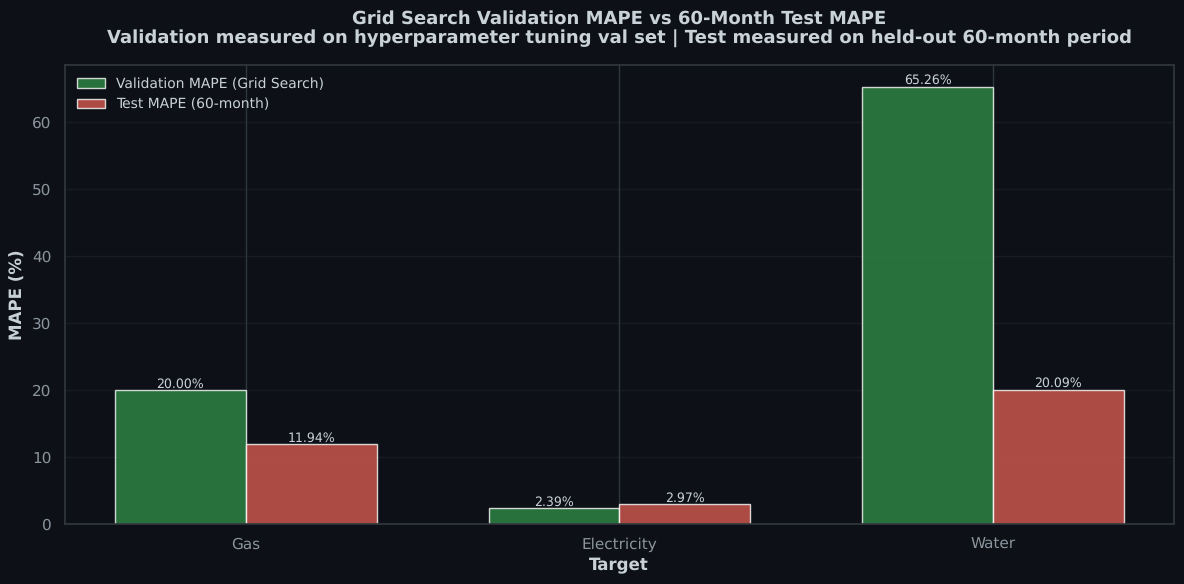

In [30]:
# Create comparison charts

# Chart: Validation MAPE (Grid Search) vs Test MAPE (60-month performance)
fig, ax = plt.subplots(figsize=(12, 6))

targets_short = ['Gas', 'Electricity', 'Water']
# Validation MAPE from grid search (before training on train+val)
validation_mapes = [
    best_params_gas['MAPE'] * 100,
    best_params_elec['MAPE'] * 100,
    best_params_water['MAPE'] * 100
]
# Current test MAPE after training on full train+val
test_mapes = [final_test_mape['Gas Consumption (tons)'], 
              final_test_mape['Electricity Consumption (MWh)'],
              final_test_mape['Water Consumption (tons)']]

x = np.arange(len(targets_short))
width = 0.35

bars1 = ax.bar(x - width/2, validation_mapes, width, label='Validation MAPE (Grid Search)', color='#2f8a46', alpha=0.8)
bars2 = ax.bar(x + width/2, test_mapes, width, label='Test MAPE (60-month)', color='#d45a4f', alpha=0.8)

# Add value labels
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.2f}%', ha='center', va='bottom', fontsize=9)

ax.set_xlabel('Target', fontsize=12, fontweight='bold')
ax.set_ylabel('MAPE (%)', fontsize=12, fontweight='bold')
ax.set_title('Grid Search Validation MAPE vs 60-Month Test MAPE\nValidation measured on hyperparameter tuning val set | Test measured on held-out 60-month period', 
             fontsize=13, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(targets_short)
ax.legend(fontsize=10, loc='upper left')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### 8.3 Forecast Uncertainty (Prediction Intervals)

A point forecast hides how uncertain a 60-month forecast is. We simulate 1,000 possible future paths from each fitted model (`simulate`) and take the 2.5th and 97.5th percentiles as a **95% prediction interval**. If the model describes the uncertainty well, about 95% of the actual test months should fall inside the interval.

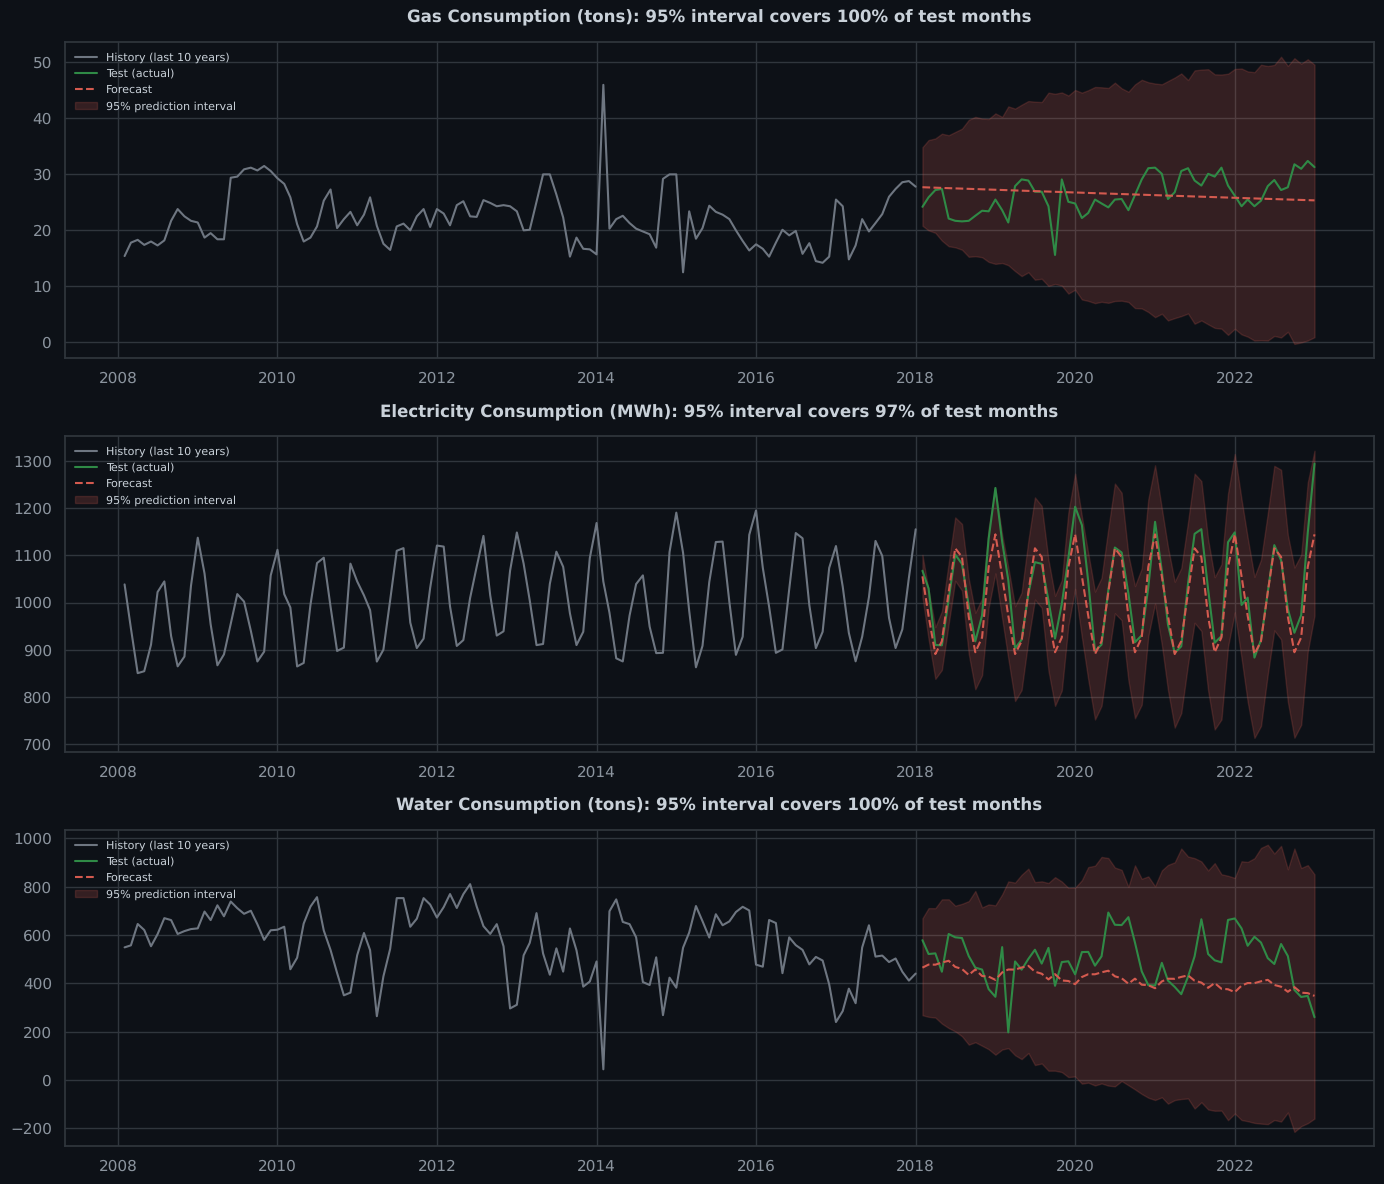

Gas Consumption (tons)           100.0
Electricity Consumption (MWh)     96.7
Water Consumption (tons)         100.0
Name: 95% PI coverage (%), dtype: float64

In [31]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
coverage = {}
for ax, (target, fitted) in zip(axes, fitted_models.items()):
    sims = fitted.simulate(nsimulations=len(test), repetitions=1000, error='add', anchor='end', random_state=42)
    lower, upper = sims.quantile(0.025, axis=1), sims.quantile(0.975, axis=1)
    actual = test[target]
    coverage[target] = ((actual.values >= lower.values) & (actual.values <= upper.values)).mean() * 100

    ax.plot(train_val.index[-120:], train_val[target].iloc[-120:], color=color_palette[5], label='History (last 10 years)')
    ax.plot(actual.index, actual, color=color_palette[2], label='Test (actual)')
    ax.plot(actual.index, final_forecasts[target], color=color_palette[4], linestyle='--', label='Forecast')
    ax.fill_between(actual.index, lower, upper, color=color_palette[4], alpha=0.2, label='95% prediction interval')
    ax.set_title(f"{target}: 95% interval covers {coverage[target]:.0f}% of test months")
    ax.legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

pd.Series(coverage, name='95% PI coverage (%)').round(1)


### 8.2 Final Forecast Evaluation Summary

**60-Month Test Set Results:**

All three energy consumption targets were forecast for the full 60-month test period (**February 2018 to January 2023**). The models were trained on the combined training and validation data (January 1990 to January 2018) and evaluated on test data they had never seen.

| Target | Test MAPE | Test MAE | Test RMSE | Assessment |
| --- | ---: | ---: | ---: | --- |
| Gas Consumption | 11.94% | 3.01 tons | 3.72 tons | **Good** |
| Electricity Consumption | **2.97%** | 31.77 MWh | 43.92 MWh | **Excellent** |
| Water Consumption | 20.09% | 101.93 tons | 129.47 tons | **Fair** |

---

## **Key Evaluation Findings:**

### **1. Generalisation (validation → test):**

-   **Electricity:** 2.39% validation MAPE → 2.97% test MAPE. The model generalises very well: the seasonal pattern it learned holds for five more years.
-   **Gas:** 20.00% → 11.94%. The test period happens to be calmer than the validation period.
-   **Water:** 65.26% → 20.09%. The huge validation MAPE was mostly caused by the February 2014 anomaly in the validation window, not by the model.

### **2. Forecast range vs actual range:**

-   **Electricity:** the forecast ranges from 891 to 1,144 MWh and follows the actual seasonal swings closely (actual mean 1,030 ± 97 MWh).
-   **Gas:** the forecast is a smooth, slowly falling line (27.7 → 25.4 tons). Because gas has no seasonality, the model cannot predict month-to-month swings; it only predicts the level.
-   **Water:** the forecast slowly falls from about 494 to 348 tons, while the actual level rises in 2020–2022. The multiplicative trend learned a decline that did not continue.

### **3. Practical Interpretation:**

-   **Electricity:** accurate enough for monthly planning (typical error about ±32 MWh, or 3%).
-   **Gas:** useful for planning the average level (about ±3 tons per month), but not for predicting individual peaks.
-   **Water:** only suitable for rough, long-term budgeting.


---

## SECTION 9: Model Diagnostics (Residual Analysis)

**Objective:** Check if models captured all patterns

**What to check:**

1. **Residuals over time** - Should look random (no patterns)
2. **Residual distribution** - Should be roughly normal
3. **Q-Q plot** - Check for normality
4. **ACF of residuals** - Should show no significant autocorrelation

**Good residuals = Good model!**


In [32]:
# Calculate residuals for each target on test set
residuals_dict = {}
residual_stats = []

for target_name, target_key in [('Gas Consumption', 'Gas Consumption (tons)'),
                                 ('Water Consumption', 'Water Consumption (tons)'),
                                 ('Electricity Consumption', 'Electricity Consumption (MWh)')]:
    
    actual = test[target_key].values
    predicted = final_forecasts[target_key].values
    residuals = actual - predicted
    residuals_dict[target_name] = residuals
    
    # Calculate statistics
    residual_mean = np.mean(residuals)
    residual_std = np.std(residuals)
    shapiro_stat, shapiro_p = shapiro(residuals)
    
    residual_stats.append({
        'Target': target_name,
        'Mean': residual_mean,
        'Std Dev': residual_std,
        'Min': np.min(residuals),
        'Max': np.max(residuals),
        'Shapiro-Wilk p-value': shapiro_p,
        'Normal Distribution?': 'Yes ✓' if shapiro_p > 0.05 else 'No ✗'
    })

residual_df = pd.DataFrame(residual_stats)
print("Residual Analysis on Test Set:\n")
print(residual_df.to_string(index=False))

Residual Analysis on Test Set:

                 Target      Mean    Std Dev         Min        Max  Shapiro-Wilk p-value Normal Distribution?
        Gas Consumption -0.072988   3.719906  -11.284796   7.006231              0.405181                Yes ✓
      Water Consumption 77.784755 103.494666 -260.205328 304.999092              0.309345                Yes ✓
Electricity Consumption 23.294782  37.229217  -60.550928 149.664163              0.029453                 No ✗


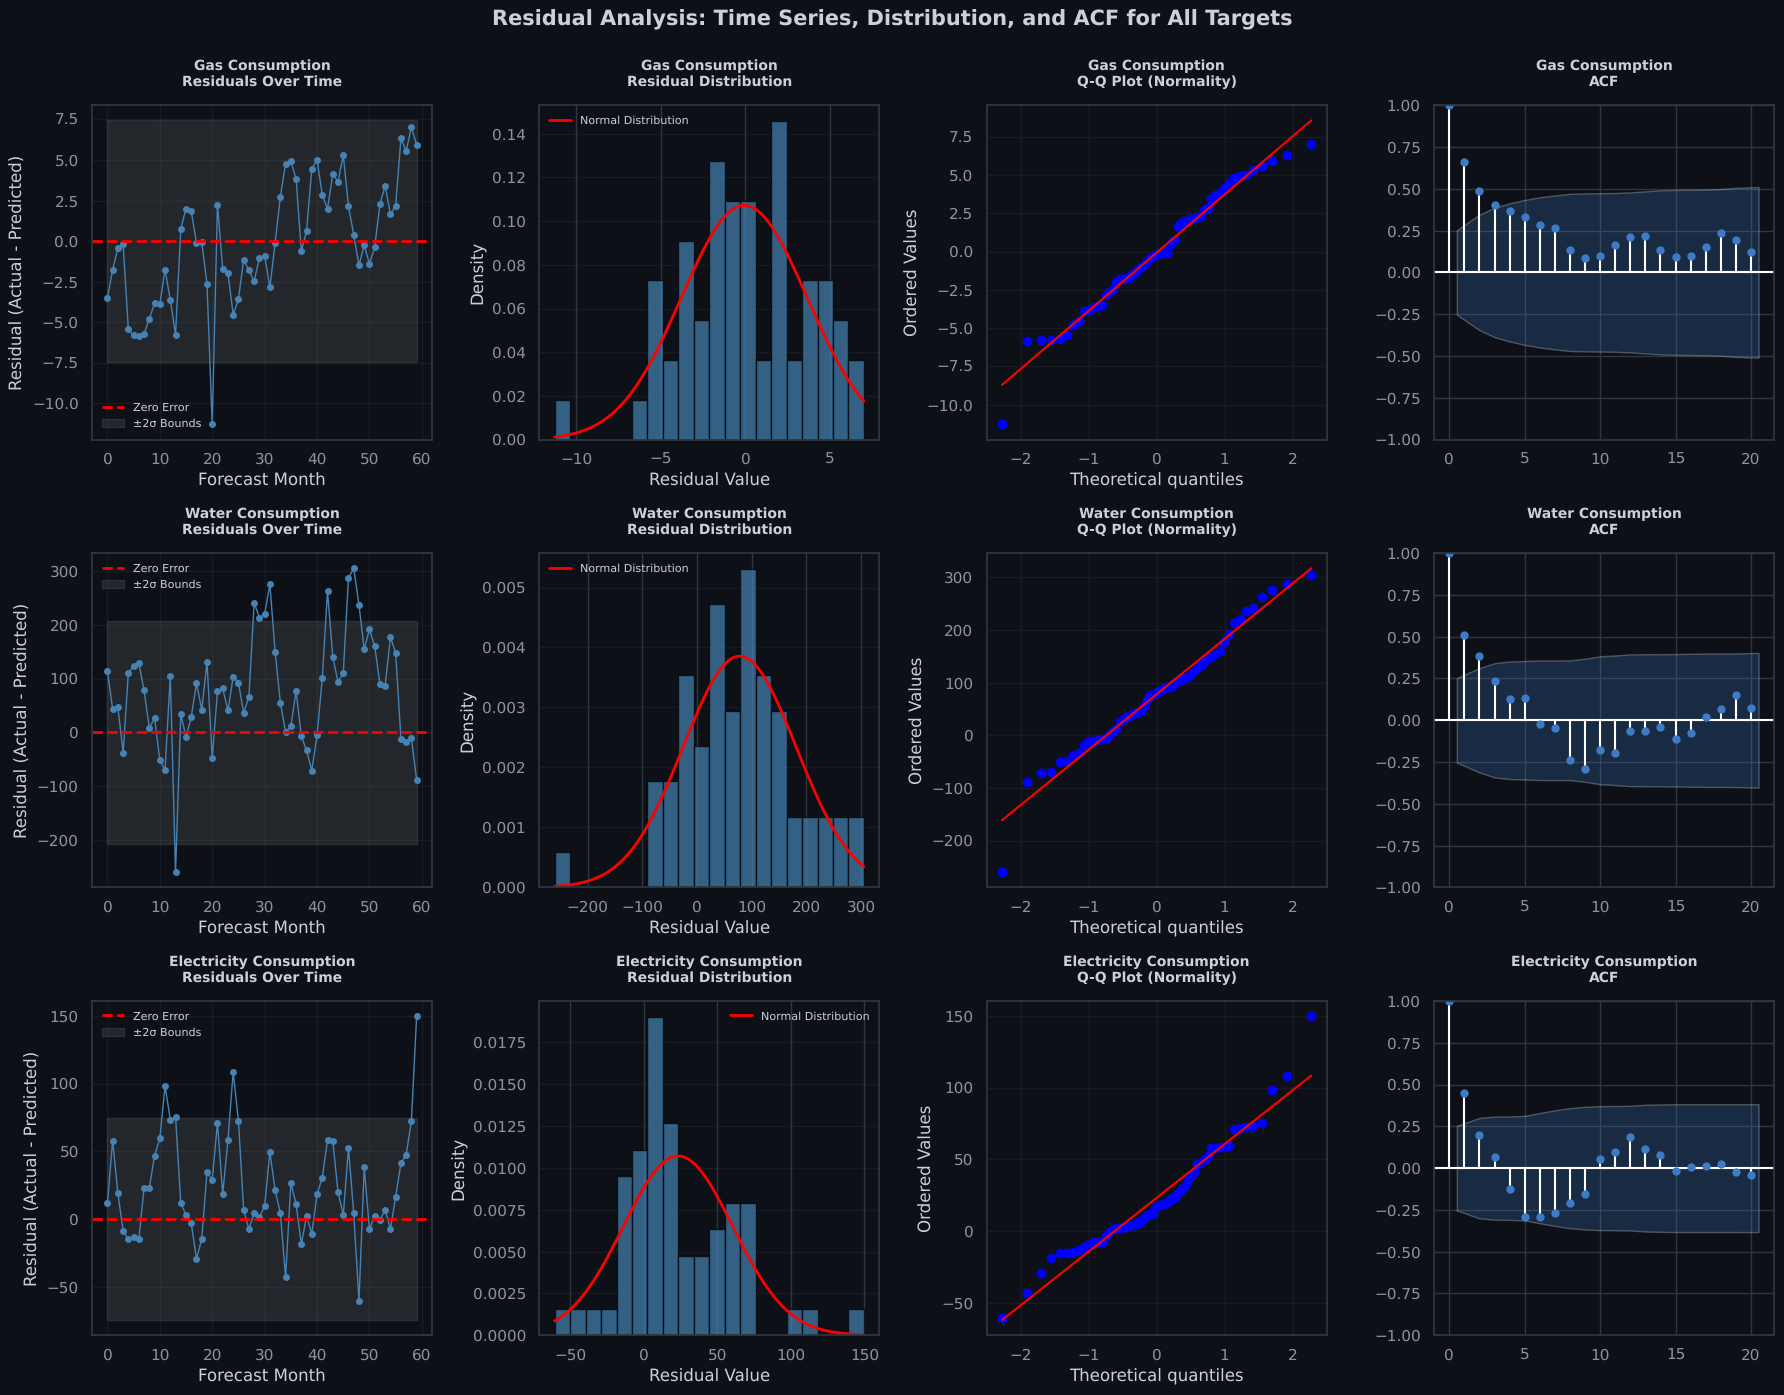

In [33]:
# Detailed residual analysis for each target
targets_analysis = ['Gas Consumption', 'Water Consumption', 'Electricity Consumption']
target_keys = ['Gas Consumption (tons)', 'Water Consumption (tons)', 'Electricity Consumption (MWh)']

fig, axes = plt.subplots(3, 4, figsize=(18, 14))
fig.suptitle('Residual Analysis: Time Series, Distribution, and ACF for All Targets', 
             fontsize=15, fontweight='bold', y=0.995)

for idx, (target_name, target_key) in enumerate(zip(targets_analysis, target_keys)):
    residuals = residuals_dict[target_name]
    time_index = np.arange(len(residuals))
    
    # 1. Residuals over time
    ax1 = axes[idx, 0]
    ax1.plot(time_index, residuals, 'o-', color='steelblue', markersize=4, linewidth=1)
    ax1.axhline(y=0, color='red', linestyle='--', linewidth=2, label='Zero Error')
    ax1.fill_between(time_index, -2*np.std(residuals), 2*np.std(residuals), 
                      alpha=0.2, color='gray', label='±2σ Bounds')
    ax1.set_title(f'{target_name}\nResiduals Over Time', fontweight='bold', fontsize=10)
    ax1.set_xlabel('Forecast Month')
    ax1.set_ylabel('Residual (Actual - Predicted)')
    ax1.legend(fontsize=8)
    ax1.grid(True, alpha=0.3)
    
    # 2. Distribution (Histogram + KDE)
    ax2 = axes[idx, 1]
    ax2.hist(residuals, bins=20, density=True, alpha=0.7, color='steelblue', edgecolor='black')
    
    # Overlay normal distribution
    mu, sigma = np.mean(residuals), np.std(residuals)
    x = np.linspace(residuals.min(), residuals.max(), 100)
    ax2.plot(x, stats.norm.pdf(x, mu, sigma), 'r-', linewidth=2, label='Normal Distribution')
    ax2.set_title(f'{target_name}\nResidual Distribution', fontweight='bold', fontsize=10)
    ax2.set_xlabel('Residual Value')
    ax2.set_ylabel('Density')
    ax2.legend(fontsize=8)
    ax2.grid(True, alpha=0.3, axis='y')
    
    # 3. Q-Q Plot (normality check)
    ax3 = axes[idx, 2]
    stats.probplot(residuals, dist="norm", plot=ax3)
    ax3.set_title(f'{target_name}\nQ-Q Plot (Normality)', fontweight='bold', fontsize=10)
    ax3.grid(True, alpha=0.3)
    
    # 4. ACF (Autocorrelation)
    ax4 = axes[idx, 3]
    plot_acf(residuals, lags=min(20, len(residuals)//2), ax=ax4, title=f'{target_name}\nAutocorrelation (ACF)')
    ax4.set_title(f'{target_name}\nACF', fontweight='bold', fontsize=10)
    
plt.tight_layout()
plt.show()

print("\n")

## 📊 RESIDUAL ANALYSIS SUMMARY

The residuals here are the 60 test-set forecast errors (actual − forecast). Because these are 1- to 60-step-ahead errors from a single forecast origin, some autocorrelation is expected: if the forecast is a little too low one month, it is usually also too low the next month.

### **Gas Consumption: Unbiased, but misses a slow drift**

The mean residual is -0.07 tons, so the forecast is unbiased overall, and the Shapiro-Wilk test does not reject normality (p = 0.41). However, the residuals drift from mostly negative in the first two years to mostly positive in the last three, and the ACF shows significant autocorrelation at the first few lags. The model forecasts a slowly falling level while actual consumption rose after 2020.

### **Electricity Consumption: Small errors, slight under-forecast**

The errors are small (standard deviation 37 MWh), and the seasonal pattern is captured well. The mean residual is +23 MWh, so the model slightly **under-forecasts**: because it has no trend component, it does not fully follow the continuing upward trend, and the error grows towards the end of the horizon (the largest residual, +150 MWh, is in the final month). Normality is rejected (p = 0.03) because of these few large late errors, and the ACF shows significant autocorrelation at lag 1 and a few later lags.

### **Water Consumption: Systematic under-forecast**

The mean residual is +78 tons, so the model consistently **under-forecasts** water: it extrapolated a downward trend that reversed after 2020. The residual standard deviation (103.5 tons) is large, and the ACF shows significant autocorrelation at lags 1–2. The residuals are roughly normal (p = 0.31).

---

### **Comparative Model Quality Assessment**

| Diagnostic Criterion | Gas | Water | Electricity |
| --- | --- | --- | --- |
| **Residual Bias (Mean ≈ 0)** | Yes ✓ | No: under-forecast (+78) ✗ | Slight under-forecast (+23) ≈ |
| **Normality (Shapiro-Wilk)** | Yes ✓ | Yes ✓ | No ✗ (a few large late errors) |
| **Independence (ACF)** | No: slow drift ✗ | No: lags 1–2 ✗ | Mostly: lag 1 ≈ |
| **Error Magnitude (MAPE)** | 11.9% | 20.1% | **3.0%** |
| **Overall Model Quality** | **Good** | **Fair** | **Excellent** |

---

### **Key Conclusions from Residual Analysis**

-   The **electricity** model captures the main structure of the series. Adding a damped trend could remove its small bias at long horizons.
-   The **gas** and **water** models are limited by the data rather than the method: without seasonality, the only thing to forecast is the level, and both levels changed direction during the test period.
-   The test residuals are autocorrelated for all three series, so a long-horizon forecast should be updated regularly as new data arrives (for example, re-fitting every month).


---

## SECTION 10: Conclusion


# Final Summary

---

## 1. Problem Statement

This project built **time series forecasting models** to predict monthly energy consumption 60 months ahead for three energy types: Gas, Electricity and Water. Accurate forecasts help energy providers plan supply, reduce costs and make infrastructure investments more effectively.

---

## 2. Dataset

**397 months (33 years) of data** from January 1990 to January 2023:

| Target | Trend | Seasonality (strength) | Notes |
| --- | --- | --- | --- |
| **Gas** | Moderate (0.56) | None (0.02) | Spike in Feb 2014 |
| **Electricity** | Strong, upward (0.96) | Strong yearly cycle (0.89) | Non-stationary (ADF p = 0.19) |
| **Water** | Moderate (0.55) | None (0.06) | Anomalous low in Feb 2014 |

---

## 3. Methodology

1. **EDA** – Visualised 33 years of data.
2. **Decomposition** – Separated trend, seasonality and noise, and measured their strength.
3. **Stationarity Testing** – ADF test: Gas and Water stationary, Electricity non-stationary.
4. **Train-Validation-Test Split** (chronological, no shuffling):
    - Train: 269 months (1990-01 to 2012-05)
    - Validation: 68 months (2012-06 to 2018-01) — for model selection
    - Test: 60 months (2018-02 to 2023-01) — used once, for the final evaluation
5. **Baseline Model** – Simple Exponential Smoothing (no trend, no seasonality).
6. **Grid Search** – 15 Holt-Winters configurations of trend, seasonality and damping per series, selected by validation MAE.
7. **Final Model** – Re-fitted on train + validation and forecast 60 months ahead.
8. **Diagnostics** – Residual analysis and 95% prediction intervals.

---

## 4. Model Improvement (validation set)

| Target | Selected configuration | Baseline MAE | Tuned MAE | Reduction |
| --- | --- | ---: | ---: | ---: |
| Gas | multiplicative trend, no seasonality | 4.84 | 4.08 | 15.8% |
| Electricity | additive seasonality, no trend | 105.42 | 24.74 | **76.5%** |
| Water | multiplicative trend and seasonality | 214.47 | 185.53 | 13.5% |

---

## 5. Final Results (60-Month Test Performance)

| Target | Test MAPE | MAE | RMSE | 95% interval coverage | Status |
| --- | ---: | ---: | ---: | ---: | --- |
| **Gas** | 11.94% | 3.01 tons | 3.72 tons | 100% | ✅ Good for level planning |
| **Electricity** | **2.97%** | 31.8 MWh | 43.9 MWh | 97% | ✅ **Ready for monthly planning** |
| **Water** | 20.09% | 101.9 tons | 129.5 tons | 100% | ⚠️ Rough budgeting only |

The 95% prediction intervals contain almost all actual test months, so the models' uncertainty estimates are trustworthy. For gas and water, however, the intervals are very wide (for water they even include negative values), which tells us honestly how uncertain those 5-year forecasts are.

---

## 6. Business Recommendations

| Target | Use Case | Recommendation |
| --- | --- | --- |
| **Electricity** | Monthly supply and grid planning | **Approved**, with regular re-fitting |
| **Gas** | Annual supply contracts (average level) | **Approved for planning**, not for predicting peaks |
| **Water** | Long-term budget estimates | **Supplement with external data** |

---

## 7. Limitations

-   **A single validation window**: model selection depends on one 68-month period. Rolling-origin (time-series) cross-validation would make the selection more robust.
-   **The February 2014 anomaly** (gas spike and water drop in the same month) looks like a data-recording problem. It falls in the validation window and inflates the validation errors; it should be investigated and possibly corrected.
-   **No external drivers**: temperature, rainfall, population and economic activity drive energy demand but are not in the data.
-   **Long horizon**: forecasting 5 years ahead from a single origin is hard, and the gas and water levels changed direction during the test period.

---

## 8. Future Improvements

1.  **Damped trend for electricity** to remove its small long-horizon under-forecast.
2.  **Rolling-origin cross-validation** for more reliable model selection.
3.  **SARIMAX with exogenous variables** such as temperature and rainfall.
4.  **Multivariate models** that use the relationships between gas, electricity and water.
5.  **Regular re-fitting** as new monthly data arrives.

---

## 9. Key Lessons Learned

-   **Use the configuration you validated.** An earlier version of this notebook dropped the tuned seasonal component for electricity when re-fitting the final model, which produced a flat forecast with 13.9% test MAPE. Keeping the validated configuration gives 3.0%.
-   **Metrics can mislead.** A single near-zero value made water's validation MAPE look catastrophic (65–71%), while the same models score about 20% on the test set. Choosing models on MAE avoids this.
-   **Seasonality is not universal.** Only electricity is seasonal; for gas and water, seasonal models do not help.
-   **Chronological splits are critical.** Shuffling time series data would leak future information into training.

---

## Final Thoughts

The best forecast is one people can trust and act on. For electricity, that is already the case; gas and water need more information than their own history to be forecast precisely.
